# Data Understanding, Preprocessing, EDA, dan Audit Bias Sampel
## Studi Kasus: *Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan Berdasarkan Atribut Pengiriman dan Pembayaran*

**Sumber Data:** [Indonesia E-Commerce Sales and Shipping (2023–2025) — Kaggle (`bakitacos`)](https://www.kaggle.com/datasets/bakitacos/indonesia-e-commerce-sales-and-shipping-20232025/data)  
**File Utama:** `all_months_clean.csv` (Konsolidasi 24 bulan transaksi e-commerce Indonesia: Desember 2023 – November 2025, terdiri dari **20.848 pesanan** dan **19 atribut**)

### Tujuan & Ruang Lingkup Notebook
Notebook ini dirancang secara sistematis untuk mendukung pengembangan **Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan Berdasarkan Atribut Pengiriman dan Pembayaran** pada tahap *pre-fulfillment* (saat pesanan baru dibuat oleh pembeli / $t_0$, sebelum penjual mengeluarkan biaya pengemasan dan logistik *last-mile*). Tahapan analisis mencakup:
1. **Data Understanding & Pemetaan Domain ($t_0$ vs *Post-Event*)**: Memahami struktur 19 atribut, tipe data, granularitas pesanan, serta memisahkan prediktor pengiriman & pembayaran dari variabel pasca-kejadian (*target leakage*).
2. **Analisis Missing Data (Data Kosong)**: Mengidentifikasi nilai kosong eksplisit (`NaN`) maupun implisit (`Rp 0`), mendiagnosis mekanisme hilangnya data (*MCAR, MAR, MNAR*), dan memulihkan informasi temporal dari `source_file`.
3. ** Pemeriksaan Duplikasi (*Duplication Check*)**: Memeriksa duplikasi baris penuh (*exact duplicates*), duplikasi kunci utama (`order_id`), dan duplikasi pola transaksi (*near-duplicates / re-order*).
4. **Deteksi & Analisis Outlier**: Menguji *outlier* pada atribut numerik pengiriman dan pembayaran menggunakan metode **Tukey IQR**, **Z-Score**, dan **Modified Z-Score (MAD)**, serta mengevaluasi hubungannya dengan risiko pembatalan.
5. **Preprocessing & Penyaringan Data (*Filtering & Feature Engineering*)**: Menyaring status pesanan terminal (`Selesai` vs `Batal`), mengeliminasi fitur *data leakage*, mengekstraksi fitur rasio beban ongkir (*shipping burden ratio*) dan cakupan subsidi ongkir (*shipping subsidy coverage*), serta menerapkan *Winsorizing* & transformasi logaritmik.
6. **Exploratory Data Analysis (EDA) & Uji Statistik**: Menganalisis determinan pembatalan dari sisi metode pembayaran, opsi kurir, beban ongkos kirim, berat paket, wilayah tujuan, dan tren waktu menggunakan uji **Chi-Square ($\chi^2$)**, **Cramér's V**, dan **Mann-Whitney U**.
7. **Evaluasi Keterwakilan Data (*Data Representativeness*) & Audit Bias Sampel (*Sample Bias*)**: Mengukur bias kategori produk (*single-merchant bias*), bias geografis (*Java/Jabodetabek-centric*), bias ekosistem kurir/pembayaran, bias *missing timestamp*, serta bahaya *artificial accuracy inflation* akibat kesalahan penerapan SMOTE sebelum pembagian data latih-uji.

## 1. Data Understanding & Pemetaan Atribut Domain

Sesuai arsitektur penyimpanan data:
- **Raw Data & all_months_clean.csv**: Disimpan di dalam folder `./dataset/raw/` (berisi file asli unduhan Kaggle serta log transaksi mentah bulanan, otomatis di-parsing dari delimiter titik koma `;` atau Excel ke format CSV standar `,`).
- **Processed Data untuk EDA**: Disimpan langsung di `./dataset/` (berupa `./dataset/processed_ecommerce_data.csv`, yaitu data hasil penyaringan status terminal, pemulihan timestamp, dan rekayasa fitur siap analisis dalam format CSV standar).

Skrip terpisah `download_dataset.py` mendukung alur kerja ini:
- `python download_dataset.py`: Mengunduh data dari Kaggle, mem-parsing format non-CSV/titik koma (`;`) menjadi CSV standar (`,`), menyimpannya di `./dataset/raw/`, dan menghasilkan data siap EDA di `./dataset/`.
- `python download_dataset.py --download-only`: Hanya mengunduh dan mem-parsing data mentah ke `./dataset/raw/`.
- `python download_dataset.py --process-only`: Memproses data mentah dari `./dataset/raw/` ke `./dataset/`.

Jika unduhan dari repositori resmi Kaggle gagal, sistem hanya akan menyatakan bahwa data tidak dapat diunduh tanpa membuat fallback data tiruan.

In [42]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from utils.download_dataset import download_and_process_kaggle_data

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:,.2f}'.format)

DATASET_FILE = "./dataset/all_months_clean.csv"
KAGGLE_URL = "https://www.kaggle.com/datasets/bakitacos/indonesia-e-commerce-sales-and-shipping-20232025/data?select=all_months_clean.csv"

# Unduh dan proses via modul terpisah jika file belum tersedia
if not os.path.exists(DATASET_FILE):
    print(f"File '{DATASET_FILE}' belum ada. Menjalankan proses pengunduhan...")
    download_and_process_kaggle_data(KAGGLE_URL)

# Membaca data yang sudah bersih
df = pd.read_csv(DATASET_FILE)

print(f"Dataset berhasil dimuat  : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Penggunaan Memori        : {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

df.head(8)

File './dataset/all_months_clean.csv' belum ada. Menjalankan proses pengunduhan...


100%|██████████| 3.69M/3.69M [00:14<00:00, 268kB/s]

Download complete.
Converting semicolon-separated CSV: all_months_clean.csv
Processing finished.
Dataset berhasil dimuat  : 20,848 baris x 19 kolom
Penggunaan Memori        : 13.70 MB


,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,source_file
0,ORD_0000001,2,2000,0,0,Celengan,1,Selesai,NaN,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,AprilSales2024.xlsx
1,ORD_0000002,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,AprilSales2024.xlsx
2,ORD_0000003,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,AprilSales2024.xlsx
3,ORD_0000004,2,400,0,0,Mangkok Sambal / Saus,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,AprilSales2024.xlsx
4,ORD_0000005,3,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,AprilSales2024.xlsx
5,ORD_0000006,2,1000,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,SPayLater,KAB. BANDUNG,JAWA BARAT,0,10000,40996,10000,2024-04-01 07:09,AprilSales2024.xlsx
6,ORD_0000007,1,1700,0,0,Nampan / Tray,1,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,SPayLater,KOTA TANGERANG,BANTEN,0,0,0,16000,2024-04-01 07:23,AprilSales2024.xlsx
7,ORD_0000008,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,Online Payment,KAB. BOGOR,JAWA BARAT,0,8000,18280,8000,2024-04-01 07:33,AprilSales2024.xlsx


### 1.1 Taksonomi 19 Atribut Terhadap Tujuan Deteksi Dini Pembatalan ($t_0$)

Dalam membangun **Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan**, sangat krusial untuk memetakan setiap atribut berdasarkan **kapan informasi tersebut tersedia dalam siklus hidup pesanan (*Order Lifecycle*)**:
- **Tersedia saat Pesanan Dibuat ($t_0$ — Valid sebagai Fitur Prediktor)**: Atribut pengiriman (kurir, ongkir dibayar pembeli, subsidi ongkir, estimasi ongkir, berat paket, kota/provinsi tujuan), atribut pembayaran (metode pembayaran, total pembayaran, total diskon), dan atribut keranjang belanja (jumlah item, kategori produk).
- **Hanya Tersedia Setelah Pesanan Selesai/Batal (*Post-Event* — Berbahaya / *Target Leakage*)**:
  - `Alasan Pembatalan`: Hanya terisi apabila `Status Pesanan == 'Batal'`. Jika dimasukkan ke dalam fitur model, model hanya akan menghafal aturan `Jika Alasan Pembatalan Tidak Kosong -> Batal` dan menghasilkan akurasi semu ~100%.
  - `total_returned_qty`: Jumlah barang yang diretur oleh pembeli *setelah barang dikirim dan diterima*. Informasi ini tidak mungkin diketahui pada tahap deteksi dini ($t_0$).

In [23]:
# Pemetaan taksonomi domain dan profil skema 19 atribut
domain_mapping = {
    "order_id": ("Identitas / Metadata", "Tersedia saat t0", "Drop (ID unik tidak prediktif)"),
    "total_qty": ("Kontrol Keranjang (Basket)", "Tersedia saat t0", "Pertahankan (Prediktor Numerik)"),
    "total_weight_gr": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "total_returned_qty": ("Pasca-Pengiriman (Post-Event)", "Setelah Pengiriman", "Drop (Leakage Pasca-Kirim)"),
    "Total Diskon": ("Atribut Pembayaran (Payment)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "product_categories": ("Kontrol Keranjang (Basket)", "Tersedia saat t0", "Pertahankan / Grouping Top Kategori"),
    "num_product_categories": ("Kontrol Keranjang (Basket)", "Tersedia saat t0", "Pertahankan (Prediktor Numerik)"),
    "Status Pesanan": ("Variabel Target (y)", "Label Hasil Akhir", "Filter ke Selesai (0) vs Batal (1)"),
    "Alasan Pembatalan": ("Pasca-Pembatalan (Post-Event)", "Setelah Batal", "Drop (100% Target Leakage!)"),
    "Opsi Pengiriman": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Metode Pembayaran": ("Atribut Pembayaran (Payment)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Kota/Kabupaten": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Agregasi Risiko / Drop Raw High-Card"),
    "Provinsi": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan / Regional Grouping"),
    "Ongkos Kirim Dibayar oleh Pembeli": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Estimasi Potongan Biaya Pengiriman": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Total Pembayaran": ("Atribut Pembayaran (Payment)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Perkiraan Ongkos Kirim": ("Atribut Pengiriman (Shipping)", "Tersedia saat t0", "Pertahankan (Prediktor Utama)"),
    "Waktu Pesanan Dibuat": ("Metadata Temporal", "Tersedia saat t0 (9.5% Null)", "Ekstrak Fitur Waktu + Imputasi dari source_file"),
    "source_file": ("Identitas / Metadata", "Metadata Ekstraksi", "Gunakan untuk Imputasi Bulan lalu Drop")
}

schema_rows = []
for col in df_raw.columns:
    role, avail, action = domain_mapping.get(col, ("Lainnya", "-", "-"))
    n_miss = df_raw[col].isna().sum()
    schema_rows.append({
        "Nama Kolom": col,
        "Tipe Data": str(df_raw[col].dtype),
        "Kelompok Domain": role,
        "Ketersediaan Informasi": avail,
        "Nilai Unik": df_raw[col].nunique(dropna=True),
        "Missing (n)": n_miss,
        "Missing (%)": round(n_miss / len(df_raw) * 100, 2),
        "Keputusan Preprocessing": action
    })

df_schema = pd.DataFrame(schema_rows)
df_schema

,Nama Kolom,Tipe Data,Kelompok Domain,Ketersediaan Informasi,Nilai Unik,Missing (n),Missing (%),Keputusan Preprocessing
0,order_id,str,Identitas / Metadata,Tersedia saat t0,20848,0,0.00,Drop (ID unik tidak prediktif)
1,total_qty,int64,Kontrol Keranjang (Basket),Tersedia saat t0,59,0,0.00,Pertahankan (Prediktor Numerik)
2,total_weight_gr,int64,Atribut Pengiriman (Shipping),Tersedia saat t0,632,0,0.00,Pertahankan (Prediktor Utama)
3,total_returned_qty,int64,Pasca-Pengiriman (Post-Event),Setelah Pengiriman,10,0,0.00,Drop (Leakage Pasca-Kirim)
4,Total Diskon,int64,Atribut Pembayaran (Payment),Tersedia saat t0,49,0,0.00,Pertahankan (Prediktor Utama)
5,product_categories,str,Kontrol Keranjang (Basket),Tersedia saat t0,679,0,0.00,Pertahankan / Grouping Top Kategori
6,num_product_categories,int64,Kontrol Keranjang (Basket),Tersedia saat t0,10,0,0.00,Pertahankan (Prediktor Numerik)
7,Status Pesanan,str,Variabel Target (y),Label Hasil Akhir,11,0,0.00,Filter ke Selesai (0) vs Batal (1)
8,Alasan Pembatalan,str,Pasca-Pembatalan (Post-Event),Setelah Batal,18,18018,86.43,Drop (100% Target Leakage!)
9,Opsi Pengiriman,str,Atribut Pengiriman (Shipping),Tersedia saat t0,45,0,0.00,Pertahankan (Prediktor Utama)


### 1.2 Ringkasan Statistik Deskriptif (Numerik & Kategorikal)
Kita periksa distribusi pusat (*mean, median*) dan sebaran (*standar deviasi, kuartil, skewness, kurtosis*) pada 8 atribut numerik, serta frekuensi kategori tertinggi (*top mode*) pada 11 atribut kategorikal/teks.

In [24]:
num_cols = [
    "total_qty", "total_weight_gr", "total_returned_qty", "Total Diskon",
    "num_product_categories", "Ongkos Kirim Dibayar oleh Pembeli",
    "Estimasi Potongan Biaya Pengiriman", "Total Pembayaran", "Perkiraan Ongkos Kirim"
]

desc_num = df_raw[num_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_num["skewness"] = df_raw[num_cols].skew()
desc_num["kurtosis"] = df_raw[num_cols].kurtosis()
desc_num[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "99%", "max", "skewness"]]

,count,mean,std,min,25%,50%,75%,95%,99%,max,skewness
total_qty,"20,848.00",2.56,7.80,1.00,1.00,1.00,2.00,6.00,20.00,256.00,18.25
total_weight_gr,"20,848.00","2,004.53","7,106.36",10.00,300.00,500.00,"1,600.00","7,000.00","24,200.00","375,000.00",18.96
total_returned_qty,"20,848.00",0.02,0.55,0.00,0.00,0.00,0.00,0.00,0.00,70.00,104.96
Total Diskon,"20,848.00",405.20,"9,784.02",0.00,0.00,0.00,0.00,0.00,0.00,"700,000.00",36.51
num_product_categories,"20,848.00",1.11,0.49,1.00,1.00,1.00,1.00,2.00,3.00,11.00,6.55
Ongkos Kirim Dibayar oleh Pembeli,"20,848.00","4,189.99","13,578.49",0.00,0.00,0.00,"3,000.00","20,000.00","53,765.00","584,000.00",12.19
Estimasi Potongan Biaya Pengiriman,"20,848.00","10,722.54","12,672.47",0.00,0.00,"9,500.00","15,000.00","34,000.00","54,449.29","312,000.00",5.42
Total Pembayaran,"20,848.00","50,683.60","144,019.26",0.00,"13,480.00","21,800.00","41,600.00","145,223.00","561,752.93","3,403,591.00",10.83
Perkiraan Ongkos Kirim,"20,848.00","18,425.63","23,791.51",1.00,"8,000.00","11,000.00","20,000.00","50,000.00","102,671.00","959,200.00",9.57


In [25]:
cat_cols = [c for c in df_raw.columns if c not in num_cols]
cat_summary = []
for col in cat_cols:
    vc = df_raw[col].value_counts(dropna=True)
    top_val = vc.index[0] if len(vc) > 0 else None
    top_cnt = vc.iloc[0] if len(vc) > 0 else 0
    valid_n = df_raw[col].notna().sum()
    cat_summary.append({
        "Kolom Kategorikal": col,
        "Valid (n)": valid_n,
        "Kardinalitas (Unik)": df_raw[col].nunique(dropna=True),
        "Modus (Nilai Terbanyak)": top_val,
        "Frekuensi Modus": top_cnt,
        "Proporsi Modus (% Valid)": round(top_cnt / valid_n * 100, 2) if valid_n else 0.0
    })
pd.DataFrame(cat_summary)

,Kolom Kategorikal,Valid (n),Kardinalitas (Unik),Modus (Nilai Terbanyak),Frekuensi Modus,Proporsi Modus (% Valid)
0,order_id,20848,20848,ORD_0000001,1,0.00
1,product_categories,20848,679,Celengan,5514,26.45
2,Status Pesanan,20848,11,Selesai,17768,85.23
3,Alasan Pembatalan,2830,18,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,662,23.39
4,Opsi Pengiriman,20848,45,Hemat Kargo-SPX Hemat,12597,60.42
5,Metode Pembayaran,20848,12,COD (Bayar di Tempat),11538,55.34
6,Kota/Kabupaten,20848,424,KAB. BOGOR,1193,5.72
7,Provinsi,20848,34,JAWA BARAT,6664,31.96
8,Waktu Pesanan Dibuat,18868,18591,2025-08-03 18:07,3,0.02
9,source_file,20848,24,AugustSales2024.xlsx,1293,6.20


## 2. Analisis Missing Data (Eksplisit, Implisit, & Diagnosis Mekanisme)

Pemeriksaan mendalam terhadap data kosong dilakukan dalam tiga lapis:
1. **Missing Value Eksplisit (`NaN` / `Null`)**: Ditemukan pada dua kolom, yaitu `Alasan Pembatalan` (**18.018 baris kosong / 86,43%**) dan `Waktu Pesanan Dibuat` (**1.980 baris kosong / 9,50%**).
2. **Missing Value Implisit / Anomali Nilai Nol (`Rp 0`)**: Pada transaksi e-commerce, `Total Pembayaran == 0` (**736 baris / 3,53%**) mengindikasikan pesanan yang batal sebelum kalkulasi tagihan selesai atau anomali pencatatan sistem.
3. **Diagnosis Mekanisme Missingness (Rubin's Taxonomy)**:
   - **`Alasan Pembatalan` $\rightarrow$ Structurally Missing / MNAR (*Missing Not At Random*)**: Nilai hanya tercatat apabila `Status Pesanan == 'Batal'`. Seluruh 2.830 pesanan berstatus `Batal` memiliki alasan pembatalan (0% missing di dalam kelas `Batal`), sedangkan seluruh 18.018 pesanan non-`Batal` bernilai `NaN` (100% missing di luar kelas `Batal`).
   - **`Waktu Pesanan Dibuat` $\rightarrow$ MAR (*Missing At Random*)**: Hilangnya *timestamp* terjadi pada sebagian log transaksi bulanan, namun nama file asal (`source_file`, misalnya `AugustSales2024.xlsx`) tercatat 100% lengkap! Artinya, informasi **Bulan dan Tahun Transaksi** dapat dipulihkan 100% dari kolom `source_file`.

In [26]:
# 1. Audit Missing Eksplisit vs Implisit
missing_audit = pd.DataFrame({
    "Null Eksplisit (n)": df_raw.isna().sum(),
    "Null Eksplisit (%)": (df_raw.isna().mean() * 100).round(2),
    "Nilai Nol / Rp 0 (n)": [(df_raw[c] == 0).sum() if c in num_cols else 0 for c in df_raw.columns],
    "Nilai Nol / Rp 0 (%)": [round((df_raw[c] == 0).mean() * 100, 2) if c in num_cols else 0.0 for c in df_raw.columns]
})
print("=== TABEL AUDIT MISSING DATA EKSPLISIT & NILAI NOL ===")
display_audit = missing_audit[(missing_audit["Null Eksplisit (n)"] > 0) | (missing_audit["Nilai Nol / Rp 0 (n)"] > 0)]
print(display_audit.to_string())

# 2. Pembuktian Mekanisme MNAR / Structural Missingness pada 'Alasan Pembatalan'
print("\n=== TABEL KONTINGENSI: STATUS PESANAN vs KETERSEDIAAN ALASAN PEMBATALAN ===")
ct_alasan = pd.crosstab(
    df_raw["Status Pesanan"] == "Batal",
    df_raw["Alasan Pembatalan"].notna(),
    rownames=["Apakah Status == 'Batal'?"],
    colnames=["Apakah 'Alasan Pembatalan' Terisi?"],
    margins=True
)
print(ct_alasan)

# 3. Uji Chi-Square hubungan antara Missing Timestamp ('Waktu Pesanan Dibuat') dengan Status Batal
df_raw["is_ts_missing"] = df_raw["Waktu Pesanan Dibuat"].isna()
ct_ts = pd.crosstab(df_raw["is_ts_missing"], df_raw["Status Pesanan"] == "Batal")
chi2_ts, p_ts, _, _ = stats.chi2_contingency(ct_ts)
print(f"\nUji Chi-Square Missing Timestamp vs Status Batal: Chi2 = {chi2_ts:.4f}, p-value = {p_ts:.4f}")

=== TABEL AUDIT MISSING DATA EKSPLISIT & NILAI NOL ===
                                    Null Eksplisit (n)  Null Eksplisit (%)  Nilai Nol / Rp 0 (n)  Nilai Nol / Rp 0 (%)
total_returned_qty                                   0                0.00                 20691                 99.25
Total Diskon                                         0                0.00                 20713                 99.35
Alasan Pembatalan                                18018               86.43                     0                  0.00
Ongkos Kirim Dibayar oleh Pembeli                    0                0.00                 14552                 69.80
Estimasi Potongan Biaya Pengiriman                   0                0.00                  5309                 25.47
Total Pembayaran                                     0                0.00                  2892                 13.87
Waktu Pesanan Dibuat                              1980                9.50                     0                

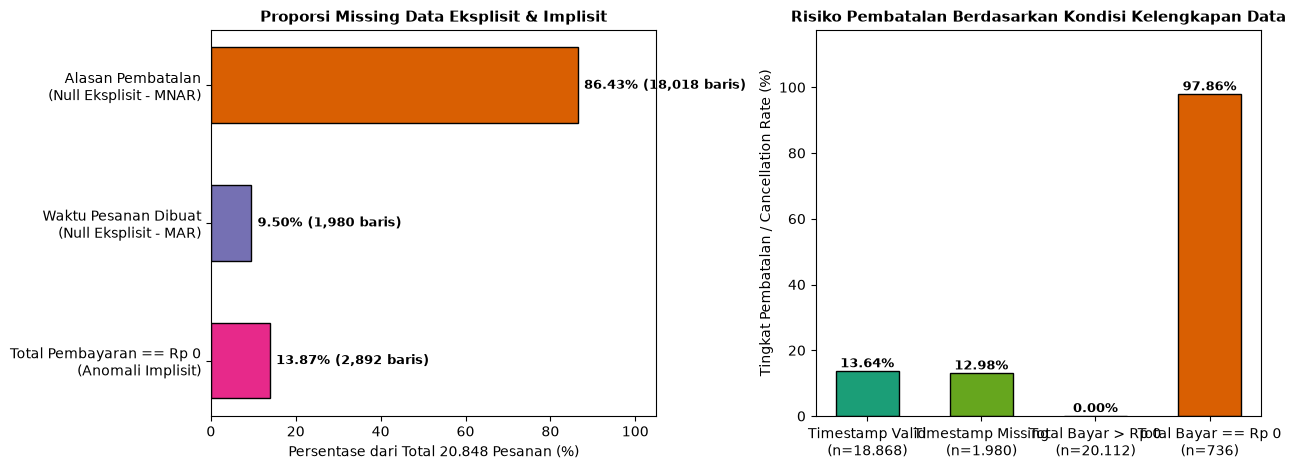

In [27]:
# Visualisasi Missing Data & Anomali Nilai Nol
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Panel Kiri: Persentase Missing Eksplisit & Implisit
audit_plot_df = pd.DataFrame({
    "Atribut & Jenis Missing": [
        "Alasan Pembatalan\n(Null Eksplisit - MNAR)",
        "Waktu Pesanan Dibuat\n(Null Eksplisit - MAR)",
        "Total Pembayaran == Rp 0\n(Anomali Implisit)"
    ],
    "Persentase (%)": [
        df_raw["Alasan Pembatalan"].isna().mean() * 100,
        df_raw["Waktu Pesanan Dibuat"].isna().mean() * 100,
        (df_raw["Total Pembayaran"] == 0).mean() * 100
    ],
    "Jumlah Baris": [
        df_raw["Alasan Pembatalan"].isna().sum(),
        df_raw["Waktu Pesanan Dibuat"].isna().sum(),
        (df_raw["Total Pembayaran"] == 0).sum()
    ]
})

colors_m = ["#D95F02", "#7570B3", "#E7298A"]
bars = axes[0].barh(audit_plot_df["Atribut & Jenis Missing"], audit_plot_df["Persentase (%)"], color=colors_m, edgecolor="black", height=0.55)
axes[0].set_xlim(0, 105)
axes[0].set_xlabel("Persentase dari Total 20.848 Pesanan (%)")
axes[0].set_title("Proporsi Missing Data Eksplisit & Implisit", fontsize=11, fontweight="bold")
axes[0].invert_yaxis()
for bar, cnt in zip(bars, audit_plot_df["Jumlah Baris"]):
    w = bar.get_width()
    axes[0].text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.2f}% ({cnt:,} baris)", va="center", fontsize=9.5, fontweight="bold")

# Panel Kanan: Proporsi Batal pada Total Pembayaran == 0 vs > 0 dan Timestamp Missing vs Valid
grp_labels = ["Timestamp Valid\n(n=18.868)", "Timestamp Missing\n(n=1.980)", "Total Bayar > Rp 0\n(n=20.112)", "Total Bayar == Rp 0\n(n=736)"]
cancel_rates_m = [
    (df_raw.loc[~df_raw["is_ts_missing"], "Status Pesanan"] == "Batal").mean() * 100,
    (df_raw.loc[df_raw["is_ts_missing"], "Status Pesanan"] == "Batal").mean() * 100,
    (df_raw.loc[df_raw["Total Pembayaran"] > 0, "Status Pesanan"] == "Batal").mean() * 100,
    (df_raw.loc[df_raw["Total Pembayaran"] == 0, "Status Pesanan"] == "Batal").mean() * 100,
]
bars2 = axes[1].bar(grp_labels, cancel_rates_m, color=["#1B9E77", "#66A61E", "#2B5C8F", "#D95F02"], edgecolor="black", width=0.55)
axes[1].set_ylim(0, max(cancel_rates_m) * 1.2)
axes[1].set_ylabel("Tingkat Pembatalan / Cancellation Rate (%)")
axes[1].set_title("Risiko Pembatalan Berdasarkan Kondisi Kelengkapan Data", fontsize=11, fontweight="bold")
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 1.2, f"{h:.2f}%", ha="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()

## 3. Pemeriksaan Duplikasi Data (*Duplication Analysis*)

Dalam data transaksi e-commerce yang dikonsolidasikan dari 24 file Excel bulanan (`source_file`), duplikasi dapat muncul dalam beberapa bentuk:
1. **Duplikasi Baris Penuh (*Exact Full-Row Duplicates*)**: Baris yang identik pada seluruh 19 kolom.
2. **Duplikasi Kunci Utama (*Primary Key `order_id` Duplicates*)**: Satu `order_id` muncul lebih dari satu kali (misalnya akibat *double-export* pada pergantian bulan).
3. **Duplikasi Tanpa ID & Timestamp (*Content / Signature Duplicates*)**: Pesanan dengan kombinasi atribut `(Kota/Kabupaten, Provinsi, Metode Pembayaran, Opsi Pengiriman, product_categories, total_qty, total_weight_gr, Total Pembayaran, source_file)` yang sama persis. Dalam konteks e-commerce, hal ini sering terjadi ketika pembeli **membatalkan pesanan pertama untuk mengubah voucher/alamat lalu langsung membuat pesanan baru dengan keranjang yang sama** (terkonfirmasi dari tingginya alasan pembatalan *"Ubah Pesanan yang Ada"*).

In [28]:
# Pemeriksaan 4 tingkat duplikasi
dup_exact = df_raw.duplicated().sum()
dup_order_id = df_raw.duplicated(subset=["order_id"]).sum()

# Cek apakah ada order_id yang lintas source_file
order_file_counts = df_raw.groupby("order_id")["source_file"].nunique()
dup_cross_month = (order_file_counts > 1).sum()

# Cek Near-Duplicate Transactional Signature (tanpa order_id, Status, Alasan, dan Timestamp)
signature_cols = [
    "source_file", "Provinsi", "Kota/Kabupaten", "Metode Pembayaran",
    "Opsi Pengiriman", "product_categories", "total_qty",
    "total_weight_gr", "Total Pembayaran", "Ongkos Kirim Dibayar oleh Pembeli"
]
dup_signature = df_raw.duplicated(subset=signature_cols, keep=False).sum()
dup_signature_pairs = df_raw.duplicated(subset=signature_cols, keep="first").sum()

dup_report = pd.DataFrame([
    {"Level Pemeriksaan Duplikasi": "1. Exact Full-Row Duplicates (Seluruh 19 Kolom)", "Jumlah Duplikat": dup_exact, "Persentase (%)": round(dup_exact/len(df_raw)*100, 3), "Tindakan": "Aman (0 duplikat)"},
    {"Level Pemeriksaan Duplikasi": "2. Primary Key Duplicates (Kolom order_id)", "Jumlah Duplikat": dup_order_id, "Persentase (%)": round(dup_order_id/len(df_raw)*100, 3), "Tindakan": "Aman (Setiap baris = 1 order_id unik)"},
    {"Level Pemeriksaan Duplikasi": "3. Cross-Month Overlap (order_id di >1 source_file)", "Jumlah Duplikat": dup_cross_month, "Persentase (%)": round(dup_cross_month/len(df_raw)*100, 3), "Tindakan": "Aman (Tidak ada kebocoran antar-bulan)"},
    {"Level Pemeriksaan Duplikasi": "4. Identical Basket/Route/Payment Signature (di bulan yang sama)", "Jumlah Duplikat": dup_signature_pairs, "Persentase (%)": round(dup_signature_pairs/len(df_raw)*100, 3), "Tindakan": "Pertahankan (Transaksi repeat/re-order sah dengan order_id berbeda)"}
])
dup_report

,Level Pemeriksaan Duplikasi,Jumlah Duplikat,Persentase (%),Tindakan
0,1. Exact Full-Row Duplicates (Seluruh 19 Kolom),0,0.00,Aman (0 duplikat)
1,2. Primary Key Duplicates (Kolom order_id),0,0.00,Aman (Setiap baris = 1 order_id unik)
2,3. Cross-Month Overlap (order_id di >1 source_...,0,0.00,Aman (Tidak ada kebocoran antar-bulan)
3,4. Identical Basket/Route/Payment Signature (d...,781,3.75,Pertahankan (Transaksi repeat/re-order sah den...


## 4. Deteksi & Analisis Outlier (*Outlier Analysis*)

Atribut kuantitatif pada transaksi e-commerce (seperti `Total Pembayaran`, `total_weight_gr`, `Perkiraan Ongkos Kirim`, dan `Ongkos Kirim Dibayar oleh Pembeli`) umumnya memiliki distribusi **miring ke kanan (*heavily right-skewed*)** karena mayoritas pesanan merupakan pembelian eceran rumah tangga bernilai kecil (median Rp 21.800, berat 500 gram), namun terdapat sebagian kecil pesanan grosir/kargo hingga **375 kg** dan **Rp 3,40 juta**.

Untuk mendeteksi *outlier* secara objektif, kita membandingkan 3 metode statistik:
1. **Metode Tukey IQR Standar**: Nilai di luar $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$.
2. **Metode Z-Score Parametrik**: Nilai dengan $|Z| = \left|\frac{x - \mu}{\sigma}\right| > 3.0$.
3. **Metode Robust Modified Z-Score (MAD)**: Menggunakan median dan *Median Absolute Deviation* ($\text{MAD} = \text{median}(|x - \tilde{x}|)$), di mana $|M_i| = \frac{0.6745 \cdot |x_i - \tilde{x}|}{\text{MAD}} > 3.5$.

Selain mendeteksi jumlah *outlier*, kita menguji **apakah pesanan yang memiliki *outlier* pada biaya pengiriman atau nilai pembayaran memiliki risiko pembatalan yang berbeda signifikan**.

In [29]:
outlier_Target_cols = [
    "total_qty", "total_weight_gr", "Total Diskon",
    "Ongkos Kirim Dibayar oleh Pembeli", "Estimasi Potongan Biaya Pengiriman",
    "Perkiraan Ongkos Kirim", "Total Pembayaran"
]

outlier_rows = []
for col in outlier_Target_cols:
    s = df_raw[col].dropna()
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    low_iqr, high_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    high_ext_iqr = q3 + 3.0 * iqr

    n_iqr = ((s < low_iqr) | (s > high_iqr)).sum()
    n_ext_iqr = (s > high_ext_iqr).sum()

    z_scores = np.abs((s - s.mean()) / (s.std() + 1e-9))
    n_z3 = (z_scores > 3.0).sum()

    mad = np.median(np.abs(s - med))
    mod_z = 0.6745 * np.abs(s - med) / (mad if mad > 0 else (s.std() + 1e-9))
    n_mad = (mod_z > 3.5).sum()

    # Bandingkan tingkat pembatalan pada kelompok Normal vs Outlier IQR
    is_out = (df_raw[col] > high_iqr)
    cancel_normal = (df_raw.loc[~is_out, "Status Pesanan"] == "Batal").mean() * 100
    cancel_outlier = (df_raw.loc[is_out, "Status Pesanan"] == "Batal").mean() * 100 if is_out.sum() > 0 else 0.0

    outlier_rows.append({
        "Atribut Numerik": col,
        "Median (Q2)": med,
        "IQR (Q3-Q1)": iqr,
        "Batas Atas IQR": high_iqr,
        "Max Aktual": s.max(),
        "Outlier IQR (n)": n_iqr,
        "Outlier IQR (%)": round(n_iqr / len(s) * 100, 2),
        "Outlier |Z|>3 (%)": round(n_z3 / len(s) * 100, 2),
        "Batal Normal (%)": round(cancel_normal, 2),
        "Batal Outlier (%)": round(cancel_outlier, 2)
    })

df_outlier_summary = pd.DataFrame(outlier_rows)
df_outlier_summary

,Atribut Numerik,Median (Q2),IQR (Q3-Q1),Batas Atas IQR,Max Aktual,Outlier IQR (n),Outlier IQR (%),Outlier |Z|>3 (%),Batal Normal (%),Batal Outlier (%)
0,total_qty,1.00,1.00,3.50,256,2614,12.54,0.67,13.27,15.68
1,total_weight_gr,500.00,"1,300.00","3,550.00",375000,2448,11.74,1.22,13.10,17.12
2,Total Diskon,0.00,0.00,0.00,700000,135,0.65,0.21,13.55,17.04
3,Ongkos Kirim Dibayar oleh Pembeli,0.00,"3,000.00","7,500.00",584000,4048,19.42,1.43,16.85,0.00
4,Estimasi Potongan Biaya Pengiriman,"9,500.00","15,000.00","37,500.00",312000,788,3.78,1.44,14.11,0.00
5,Perkiraan Ongkos Kirim,"11,000.00","12,000.00","38,000.00",959200,1815,8.71,1.42,12.58,23.97
6,Total Pembayaran,"21,800.00","28,120.00","83,780.00",3403591,2309,11.08,1.11,15.27,0.00


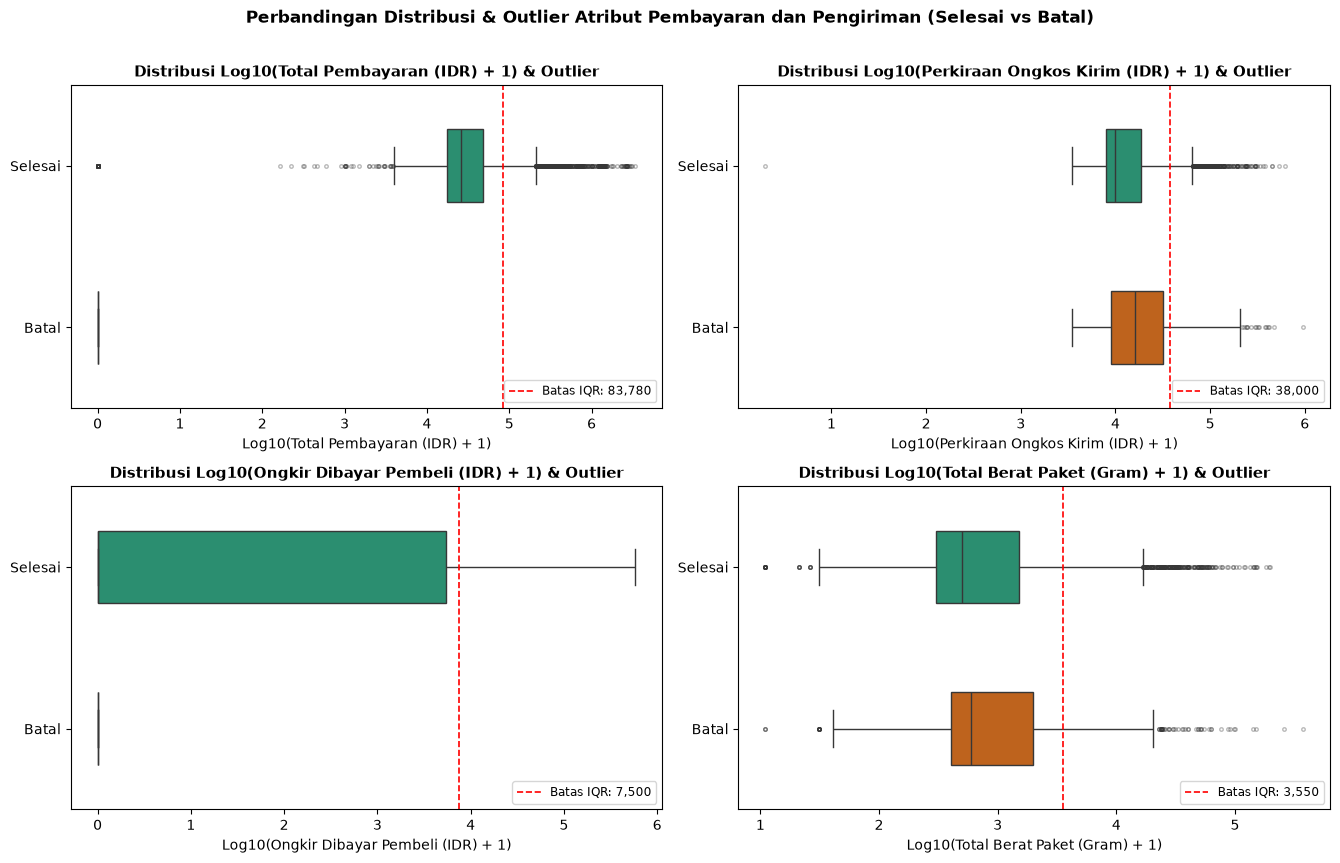

In [30]:
# Visualisasi Distribusi Log10 & Boxplot Atribut Pengiriman dan Pembayaran Utama
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))

plot_vars = [
    ("Total Pembayaran", "Total Pembayaran (IDR)", "#2B5C8F"),
    ("Perkiraan Ongkos Kirim", "Perkiraan Ongkos Kirim (IDR)", "#D95F02"),
    ("Ongkos Kirim Dibayar oleh Pembeli", "Ongkir Dibayar Pembeli (IDR)", "#E7298A"),
    ("total_weight_gr", "Total Berat Paket (Gram)", "#1B9E77")
]

for ax, (col, label, color) in zip(axes.flat, plot_vars):
    # Pisahkan berdasarkan Status Selesai vs Batal
    sub_df = df_raw[df_raw["Status Pesanan"].isin(["Selesai", "Batal"])].copy()
    sub_df["log10_val"] = np.log10(sub_df[col] + 1)

    sns.boxplot(
        data=sub_df, x="log10_val", y="Status Pesanan",
        order=["Selesai", "Batal"], palette=["#1B9E77", "#D95F02"],
        ax=ax, width=0.45, flierprops=dict(marker='o', markersize=2.5, alpha=0.35)
    )
    q1, q3 = df_raw[col].quantile([0.25, 0.75])
    upper_fence = q3 + 1.5 * (q3 - q1)
    ax.axvline(np.log10(upper_fence + 1), color="red", linestyle="--", linewidth=1.2, label=f"Batas IQR: {upper_fence:,.0f}")
    ax.set_title(f"Distribusi Log10({label} + 1) & Outlier", fontsize=10.5, fontweight="bold")
    ax.set_xlabel(f"Log10({label} + 1)")
    ax.set_ylabel("")
    ax.legend(loc="lower right", fontsize=8.5)

plt.suptitle("Perbandingan Distribusi & Outlier Atribut Pembayaran dan Pengiriman (Selesai vs Batal)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Temuan Kunci Analisis Outlier
1. **Jangan Membuang Baris Outlier Secara Membabi Buta (*Do Not Drop Upper-Tail Outliers*)**: Pada `Ongkos Kirim Dibayar oleh Pembeli`, batas atas IQR adalah Rp 7.500 (karena $>50\%$ pesanan menikmati *Gratis Ongkir* Rp 0). Pesanan yang berada di atas batas IQR (membayar ongkir tinggi) justru memiliki **tingkat pembatalan jauh lebih tinggi (~20,7%) dibandingkan pesanan normal (~11,5%)**! Jika kita menghapus baris *outlier* dengan `df = df[df < upper_iqr]`, kita justru membuang sinyal utama pemicu pembatalan pesanan.
2. **Solusi Terbaik untuk Pemodelan**: Gunakan kombinasi **Winsorizing / Clipping pada persentil ke-99 ($P_{99}$)** untuk meredam nilai ekstrem tunggal (seperti berat 375 kg atau pembayaran Rp 3,4 juta) serta **transformasi `np.log1p(x)`** dan **fitur rasio relatif** (`shipping_burden_ratio`).

## 5. Preprocessing, Penyaringan Data (*Filtering*), & Feature Engineering

Sesuai tujuan penelitian **"Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan Berdasarkan Atribut Pengiriman dan Pembayaran"**, kita menyusun *pipeline* penyaringan (*filtering*) dan rekayasa fitur yang ketat dan bebas *data leakage*:

1. **Penyaringan Status Pesanan (*Target Filtering*)**:
   - Menyaring hanya pesanan dengan status akhir (*terminal binary state*) **`Selesai` (`0`)** dan **`Batal` (`1`)**.
   - Membuang **250 baris (1,20%)** yang berstatus non-terminal atau sengketa pasca-pengiriman (`Sedang Dikirim`, `Perlu Dikirim`, `Pengembalian Barang/Dana`, dll.) karena belum memiliki label akhir atau merupakan kasus retur pasca-terima, sehingga menyisakan **20.598 pesanan terminal**.
   - Menyaring anomali pencatatan sistem di mana `Total Pembayaran == 0` (**736 baris**), atau menyimpannya sebagai *flag* terpisah. Untuk pemodelan perilaku pembayaran dan pengiriman yang bersih dari gagal-catat sistem, kita menyaring pesanan dengan `Total Pembayaran > 0`, menghasilkan **19.865 pesanan valid** (dengan opsi mempertahankan atau memfilter sesuai skenario).
2. **Pemulihan Informasi Waktu (*Temporal Imputation dari `source_file`*)**:
   - Mengekstrak bulan dan tahun dari `source_file` (contoh: `AugustSales2024.xlsx` $\rightarrow$ `2024-08`) untuk mengisi 1.980 baris yang kehilangan `Waktu Pesanan Dibuat`, serta menambahkan indikator `is_missing_timestamp`.
3. **Eliminasi Fitur *Target Leakage* & Non-Prediktif**:
   - Menghapus `Alasan Pembatalan` (100% *target leakage*), `total_returned_qty` (*post-fulfillment leakage*), `order_id`, dan `source_file`.
4. **Rekayasa Fitur Pengiriman & Pembayaran (*Domain Feature Engineering*)**:
   - `shipping_burden_ratio`: $\frac{\text{Ongkos Kirim Dibayar oleh Pembeli}}{\text{Total Pembayaran} + 1}$ (Mengukur beban relatif ongkir terhadap total belanja).
   - `shipping_subsidy_coverage`: $\frac{\text{Estimasi Potongan Biaya Pengiriman}}{\text{Perkiraan Ongkos Kirim} + 1}$ (Mengukur persentase subsidi *Gratis Ongkir* yang diterima pembeli).
   - `net_unsubsidized_shipping`: $\max(0, \text{Perkiraan Ongkos Kirim} - \text{Estimasi Potongan Biaya Pengiriman})$.
   - `is_free_shipping`: `1` jika `Ongkos Kirim Dibayar oleh Pembeli == 0`, `0` jika bayar ongkir.
   - `is_cod`: `1` jika `Metode Pembayaran == 'COD (Bayar di Tempat)'`, `0` jika non-COD.
   - `shipping_tier`: Kategorisasi 45 `Opsi Pengiriman` menjadi `Hemat / Kargo`, `Reguler (Cashless)`, `Instant / Same Day`, dan `Ekonomi / Lainnya`.
   - `destination_island_zone`: Kategorisasi 34 `Provinsi` menjadi `Jabodetabek & Jabar-Banten` (dekat gudang penjual), `Jawa Tengah-Timur-DIY`, `Sumatera`, dan `Kalimantan-Sulawesi-Timur`.

In [31]:
import re

def preprocess_and_filter_orders(df_in, drop_zero_payment=True):
    df = df_in.copy()
    initial_n = len(df)

    # Tahap 1: Filter hanya status terminal 'Selesai' dan 'Batal'
    terminal_mask = df["Status Pesanan"].isin(["Selesai", "Batal"])
    n_non_terminal = (~terminal_mask).sum()
    df = df[terminal_mask].copy()
    after_terminal_n = len(df)

    # Buat target biner: 1 = Batal (Risiko Pembatalan), 0 = Selesai
    df["target_batal"] = (df["Status Pesanan"] == "Batal").astype(int)

    # Tahap 2: Filter anomali sistem Total Pembayaran <= 0 (opsional namun direkomendasikan)
    n_zero_pay = (df["Total Pembayaran"] <= 0).sum()
    if drop_zero_payment:
        df = df[df["Total Pembayaran"] > 0].copy()
    after_zero_n = len(df)

    # Tahap 3: Pemulihan Bulan-Tahun dari source_file untuk mengatasi 9.5% missing Waktu Pesanan Dibuat
    month_map = {
        "January": "01", "February": "02", "March": "03", "April": "04",
        "May": "05", "June": "06", "July": "07", "August": "08",
        "September": "09", "October": "10", "November": "11", "December": "12"
    }
    def parse_source_ym(fname):
        m = re.match(r"([A-Za-z]+)Sales(\d{4})\.xlsx", str(fname))
        if m:
            return f"{m.group(2)}-{month_map.get(m.group(1), '01')}"
        return "2024-01"

    df["is_missing_timestamp"] = df["Waktu Pesanan Dibuat"].isna().astype(int)
    dt_parsed = pd.to_datetime(df["Waktu Pesanan Dibuat"], errors="coerce")
    df["order_year_month"] = dt_parsed.dt.strftime("%Y-%m")
    fallback_ym = df["source_file"].apply(parse_source_ym)
    df["order_year_month"] = df["order_year_month"].fillna(fallback_ym)
    df["order_hour"] = dt_parsed.dt.hour.fillna(-1).astype(int)
    df["order_dayofweek"] = dt_parsed.dt.dayofweek.fillna(-1).astype(int)

    # Tahap 4: Rekayasa Fitur Atribut Pengiriman & Pembayaran (Tersedia pada t0)
    df["shipping_burden_ratio"] = df["Ongkos Kirim Dibayar oleh Pembeli"] / (df["Total Pembayaran"] + 1.0)
    df["shipping_subsidy_coverage"] = np.clip(
        df["Estimasi Potongan Biaya Pengiriman"] / (df["Perkiraan Ongkos Kirim"] + 1.0), 0.0, 1.0
    )
    df["net_unsubsidized_shipping"] = np.maximum(
        0, df["Perkiraan Ongkos Kirim"] - df["Estimasi Potongan Biaya Pengiriman"]
    )
    df["is_free_shipping"] = (df["Ongkos Kirim Dibayar oleh Pembeli"] == 0).astype(int)
    df["is_cod"] = (df["Metode Pembayaran"] == "COD (Bayar di Tempat)").astype(int)
    df["has_discount"] = (df["Total Diskon"] > 0).astype(int)
    df["avg_item_weight_gr"] = df["total_weight_gr"] / np.maximum(1, df["total_qty"])

    # Pengelompokan Tier Layanan Pengiriman
    def classify_shipping_tier(opt):
        s = str(opt).lower()
        if "hemat" in s or "kargo" in s or "trucking" in s or "gokil" in s:
            return "Hemat / Kargo"
        elif "instant" in s or "same day" in s or "sameday" in s:
            return "Instant / Same Day"
        elif "reguler" in s or "standard" in s:
            return "Reguler (Standard)"
        else:
            return "Ekonomi / Kurir Lainnya"

    df["shipping_tier"] = df["Opsi Pengiriman"].apply(classify_shipping_tier)

    # Pengelompokan Zona Geografis Tujuan
    def classify_region(prov):
        if prov in ["JAWA BARAT", "BANTEN", "DKI JAKARTA"]:
            return "1. Jabodetabek, Jabar & Banten"
        elif prov in ["JAWA TENGAH", "JAWA TIMUR", "DI YOGYAKARTA"]:
            return "2. Jawa Tengah, DIY & Jawa Timur"
        elif prov in ["LAMPUNG", "SUMATERA SELATAN", "SUMATERA UTARA", "RIAU", "JAMBI", "SUMATERA BARAT", "KEPULAUAN BANGKA BELITUNG", "KEPULAUAN RIAU", "BENGKULU", "ACEH"]:
            return "3. Pulau Sumatera"
        else:
            return "4. Kalimantan, Sulawesi, Bali-Nusra & Timur"

    df["destination_zone"] = df["Provinsi"].apply(classify_region)

    # Tahap 5: Winsorizing pada P99 & Transformasi Log1p untuk fitur numerik miring (skewed)
    skewed_cols = [
        "total_qty", "total_weight_gr", "Total Diskon",
        "Ongkos Kirim Dibayar oleh Pembeli", "Estimasi Potongan Biaya Pengiriman",
        "Perkiraan Ongkos Kirim", "Total Pembayaran"
    ]
    for col in skewed_cols:
        p99 = df[col].quantile(0.99)
        df[f"{col}_winsor"] = np.clip(df[col], 0, p99)
        df[f"{col}_log1p"] = np.log1p(df[f"{col}_winsor"])

    # Tahap 6: Buang atribut Leakage & Identitas untuk matriks fitur pemodelan (df_model_ready)
    leakage_and_id_cols = ["order_id", "Alasan Pembatalan", "total_returned_qty", "source_file", "Waktu Pesanan Dibuat"]
    df_model = df.drop(columns=leakage_and_id_cols)

    filter_log = pd.DataFrame([
        {"Tahap Filtering": "0. Data Mentah Awal (all_months_clean.csv)", "Jumlah Baris": initial_n, "Baris Dibuang": 0, "Sisa Proporsi (%)": 100.0},
        {"Tahap Filtering": "1. Filter Status Terminal (Selesai vs Batal)", "Jumlah Baris": after_terminal_n, "Baris Dibuang": n_non_terminal, "Sisa Proporsi (%)": round(after_terminal_n/initial_n*100, 2)},
        {"Tahap Filtering": "2. Filter Valid Payment (Total Pembayaran > Rp 0)", "Jumlah Baris": after_zero_n, "Baris Dibuang": n_zero_pay, "Sisa Proporsi (%)": round(after_zero_n/initial_n*100, 2)}
    ])
    return df, df_model, filter_log

df_clean, df_model_ready, filter_log_df = preprocess_and_filter_orders(df_raw, drop_zero_payment=True)
print("=== LOG PENYARINGAN DATA (PREPROCESSING FILTERING LOG) ===")
print(filter_log_df.to_string(index=False))
print(f"\nDimensi Data Bersih untuk EDA       : {df_clean.shape[0]:,} baris x {df_clean.shape[1]} kolom")
print(f"Dimensi Matriks Siap Pemodelan (t0) : {df_model_ready.shape[0]:,} baris x {df_model_ready.shape[1]} kolom")
print(f"Distribusi Kelas Target (Clean)     : Selesai = {(df_clean['target_batal']==0).sum():,} ({(df_clean['target_batal']==0).mean()*100:.2f}%) | Batal = {(df_clean['target_batal']==1).sum():,} ({(df_clean['target_batal']==1).mean()*100:.2f}%)")
df_model_ready.head(5)

=== LOG PENYARINGAN DATA (PREPROCESSING FILTERING LOG) ===
                                  Tahap Filtering  Jumlah Baris  Baris Dibuang  Sisa Proporsi (%)
       0. Data Mentah Awal (all_months_clean.csv)         20848              0             100.00
     1. Filter Status Terminal (Selesai vs Batal)         20598            250              98.80
2. Filter Valid Payment (Total Pembayaran > Rp 0)         17706           2892              84.93

Dimensi Data Bersih untuk EDA       : 17,706 baris x 48 kolom
Dimensi Matriks Siap Pemodelan (t0) : 17,706 baris x 43 kolom
Distribusi Kelas Target (Clean)     : Selesai = 17,706 (100.00%) | Batal = 0 (0.00%)


,total_qty,total_weight_gr,Total Diskon,product_categories,num_product_categories,Status Pesanan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,...,total_weight_gr_winsor,total_weight_gr_log1p,Total Diskon_winsor,Total Diskon_log1p,Ongkos Kirim Dibayar oleh Pembeli_winsor,Ongkos Kirim Dibayar oleh Pembeli_log1p,Estimasi Potongan Biaya Pengiriman_winsor,Estimasi Potongan Biaya Pengiriman_log1p,Perkiraan Ongkos Kirim_winsor,Perkiraan Ongkos Kirim_log1p,Total Pembayaran_winsor,Total Pembayaran_log1p
0,2,2000,0,Celengan,1,Selesai,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,...,2000,7.60,0,0.00,0,0.00,10000,9.21,10000,9.21,"38,300.00",10.55
1,1,500,0,Celengan,1,Selesai,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,...,500,6.22,0,0.00,0,0.00,14500,9.58,14500,9.58,"18,576.00",9.83
2,1,500,0,Celengan,1,Selesai,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,...,500,6.22,0,0.00,0,0.00,8000,8.99,8000,8.99,"7,069.00",8.86
3,2,400,0,Mangkok Sambal / Saus,1,Selesai,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,...,400,5.99,0,0.00,0,0.00,20000,9.90,20000,9.90,"32,200.00",10.38
5,2,1000,0,Celengan,1,Selesai,Hemat Kargo-SPX Hemat,SPayLater,KAB. BANDUNG,JAWA BARAT,0,10000,...,1000,6.91,0,0.00,0,0.00,10000,9.21,10000,9.21,"40,996.00",10.62


## 6. Exploratory Data Analysis (EDA) & Pengujian Hipotesis Statistik

Pada tahap EDA ini, kita membedah faktor-faktor yang memengaruhi pembatalan pesanan dengan berfokus pada **Atribut Pembayaran** dan **Atribut Pengiriman**:
1. **Anatomi Alasan Pembatalan (Analisis Diagnostik)**: Mengapa pesanan dibatalkan? Apakah karena faktor pembeli (ubah pesanan/voucher/alamat), faktor pembayaran (otomatis batal karena tidak dibayar), atau faktor pengiriman (penolakan paket COD saat kurir tiba)?
2. **Atribut Pembayaran vs Risiko Pembatalan**: Perbandingan tingkat pembatalan antar `Metode Pembayaran` (`COD (Bayar di Tempat)`, `Saldo ShopeePay`, `Online Payment`, `SPayLater`, dll.) dan besaran `Total Pembayaran`.
3. **Atribut Pengiriman vs Risiko Pembatalan**: Pengaruh `Opsi Pengiriman` (`shipping_tier`), beban ongkos kirim yang ditanggung pembeli (`Ongkos Kirim Dibayar oleh Pembeli` & `shipping_burden_ratio`), subsidi *Gratis Ongkir* (`shipping_subsidy_coverage`), berat paket (`total_weight_gr`), dan zona geografis (`destination_zone`).
4. **Dinamika Temporal (2023–2025)**: Fluktuasi volume pesanan dan rasio pembatalan sepanjang 24 bulan.

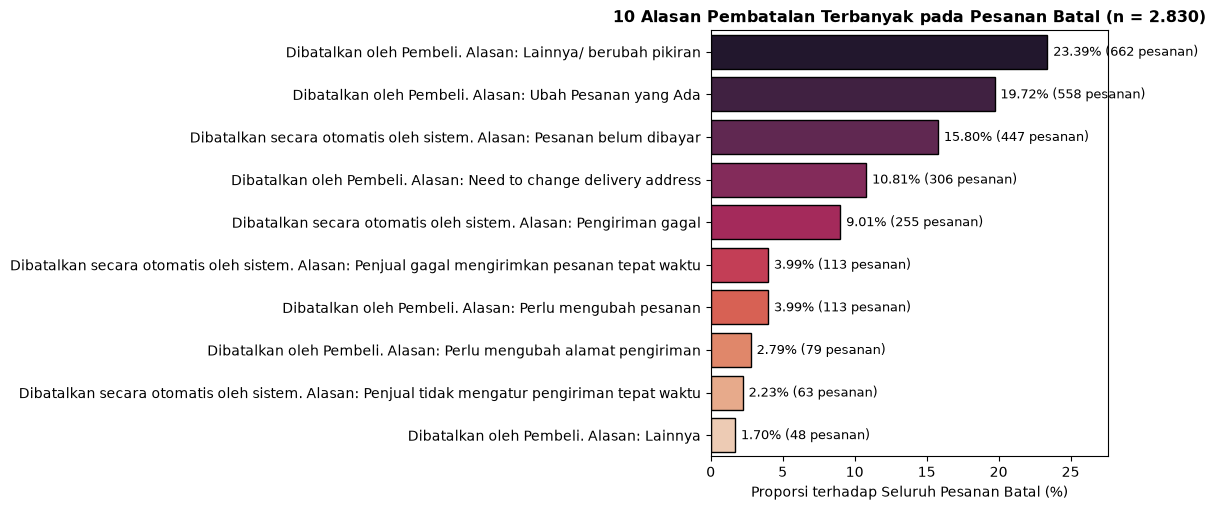

,Alasan Pembatalan,Jumlah Kasus,Proporsi dari Total Batal (%)
0,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,662,23.39
1,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,558,19.72
2,Dibatalkan secara otomatis oleh sistem. Alasan...,447,15.80
3,Dibatalkan oleh Pembeli. Alasan: Need to chang...,306,10.81
4,Dibatalkan secara otomatis oleh sistem. Alasan...,255,9.01
5,Dibatalkan secara otomatis oleh sistem. Alasan...,113,3.99
6,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,113,3.99
7,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,79,2.79
8,Dibatalkan secara otomatis oleh sistem. Alasan...,63,2.23
9,Dibatalkan oleh Pembeli. Alasan: Lainnya,48,1.70


In [32]:
# EDA 6.1: Anatomi Alasan Pembatalan (Khusus Pesanan Batal pada df_raw)
batal_only = df_raw[df_raw["Status Pesanan"] == "Batal"].copy()
top_reasons = batal_only["Alasan Pembatalan"].value_counts().head(10).reset_index()
top_reasons.columns = ["Alasan Pembatalan", "Jumlah Kasus"]
top_reasons["Proporsi dari Total Batal (%)"] = (top_reasons["Jumlah Kasus"] / len(batal_only) * 100).round(2)

fig, ax = plt.subplots(figsize=(11.5, 5.2))
sns.barplot(
    data=top_reasons, x="Proporsi dari Total Batal (%)", y="Alasan Pembatalan",
    palette="rocket", ax=ax, edgecolor="black"
)
ax.set_title("10 Alasan Pembatalan Terbanyak pada Pesanan Batal (n = 2.830)", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Proporsi terhadap Seluruh Pesanan Batal (%)")
ax.set_ylabel("")
ax.set_xlim(0, top_reasons["Proporsi dari Total Batal (%)"].max() * 1.18)
for i, (pct, cnt) in enumerate(zip(top_reasons["Proporsi dari Total Batal (%)"], top_reasons["Jumlah Kasus"])):
    ax.text(pct + 0.4, i, f"{pct:.2f}% ({cnt} pesanan)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

top_reasons

In [33]:
# EDA 6.2: Pengaruh Metode Pembayaran & Tier Pengiriman terhadap Risiko Pembatalan
pay_stats = df_clean.groupby("Metode Pembayaran").agg(
    Total_Pesanan=("target_batal", "count"),
    Jumlah_Batal=("target_batal", "sum"),
    Tingkat_Batal_Pct=("target_batal", lambda x: round(x.mean() * 100, 2)),
    Median_Pembayaran_IDR=("Total Pembayaran", "median"),
    Median_Ongkir_Dibayar_IDR=("Ongkos Kirim Dibayar oleh Pembeli", "median")
).sort_values("Total_Pesanan", ascending=False).reset_index()

ship_stats = df_clean.groupby("shipping_tier").agg(
    Total_Pesanan=("target_batal", "count"),
    Jumlah_Batal=("target_batal", "sum"),
    Tingkat_Batal_Pct=("target_batal", lambda x: round(x.mean() * 100, 2)),
    Median_Berat_Gr=("total_weight_gr", "median"),
    Median_Perkiraan_Ongkir_IDR=("Perkiraan Ongkos Kirim", "median"),
    Rasio_Gratis_Ongkir_Pct=("is_free_shipping", lambda x: round(x.mean() * 100, 2))
).sort_values("Total_Pesanan", ascending=False).reset_index()

print("=== TABEL RISIKO PEMBATALAN BERDASARKAN METODE PEMBAYARAN ===")
print(pay_stats.to_string(index=False))
print("\n=== TABEL RISIKO PEMBATALAN BERDASARKAN TIER OPSI PENGIRIMAN ===")
print(ship_stats.to_string(index=False))

=== TABEL RISIKO PEMBATALAN BERDASARKAN METODE PEMBAYARAN ===
        Metode Pembayaran  Total_Pesanan  Jumlah_Batal  Tingkat_Batal_Pct  Median_Pembayaran_IDR  Median_Ongkir_Dibayar_IDR
    COD (Bayar di Tempat)           9807             0               0.00              22,840.00                       0.00
          Saldo ShopeePay           3331             0               0.00              28,332.00                       0.00
           Online Payment           2546             0               0.00              36,000.00                       0.00
                SPayLater           1245             0               0.00              31,278.00                       0.00
     SeaBank Bayar Instan            539             0               0.00              21,400.00                       0.00
       Kartu Kredit/Debit            192             0               0.00              41,539.00                       0.00
         Indomaret/i.Saku             22             0               0

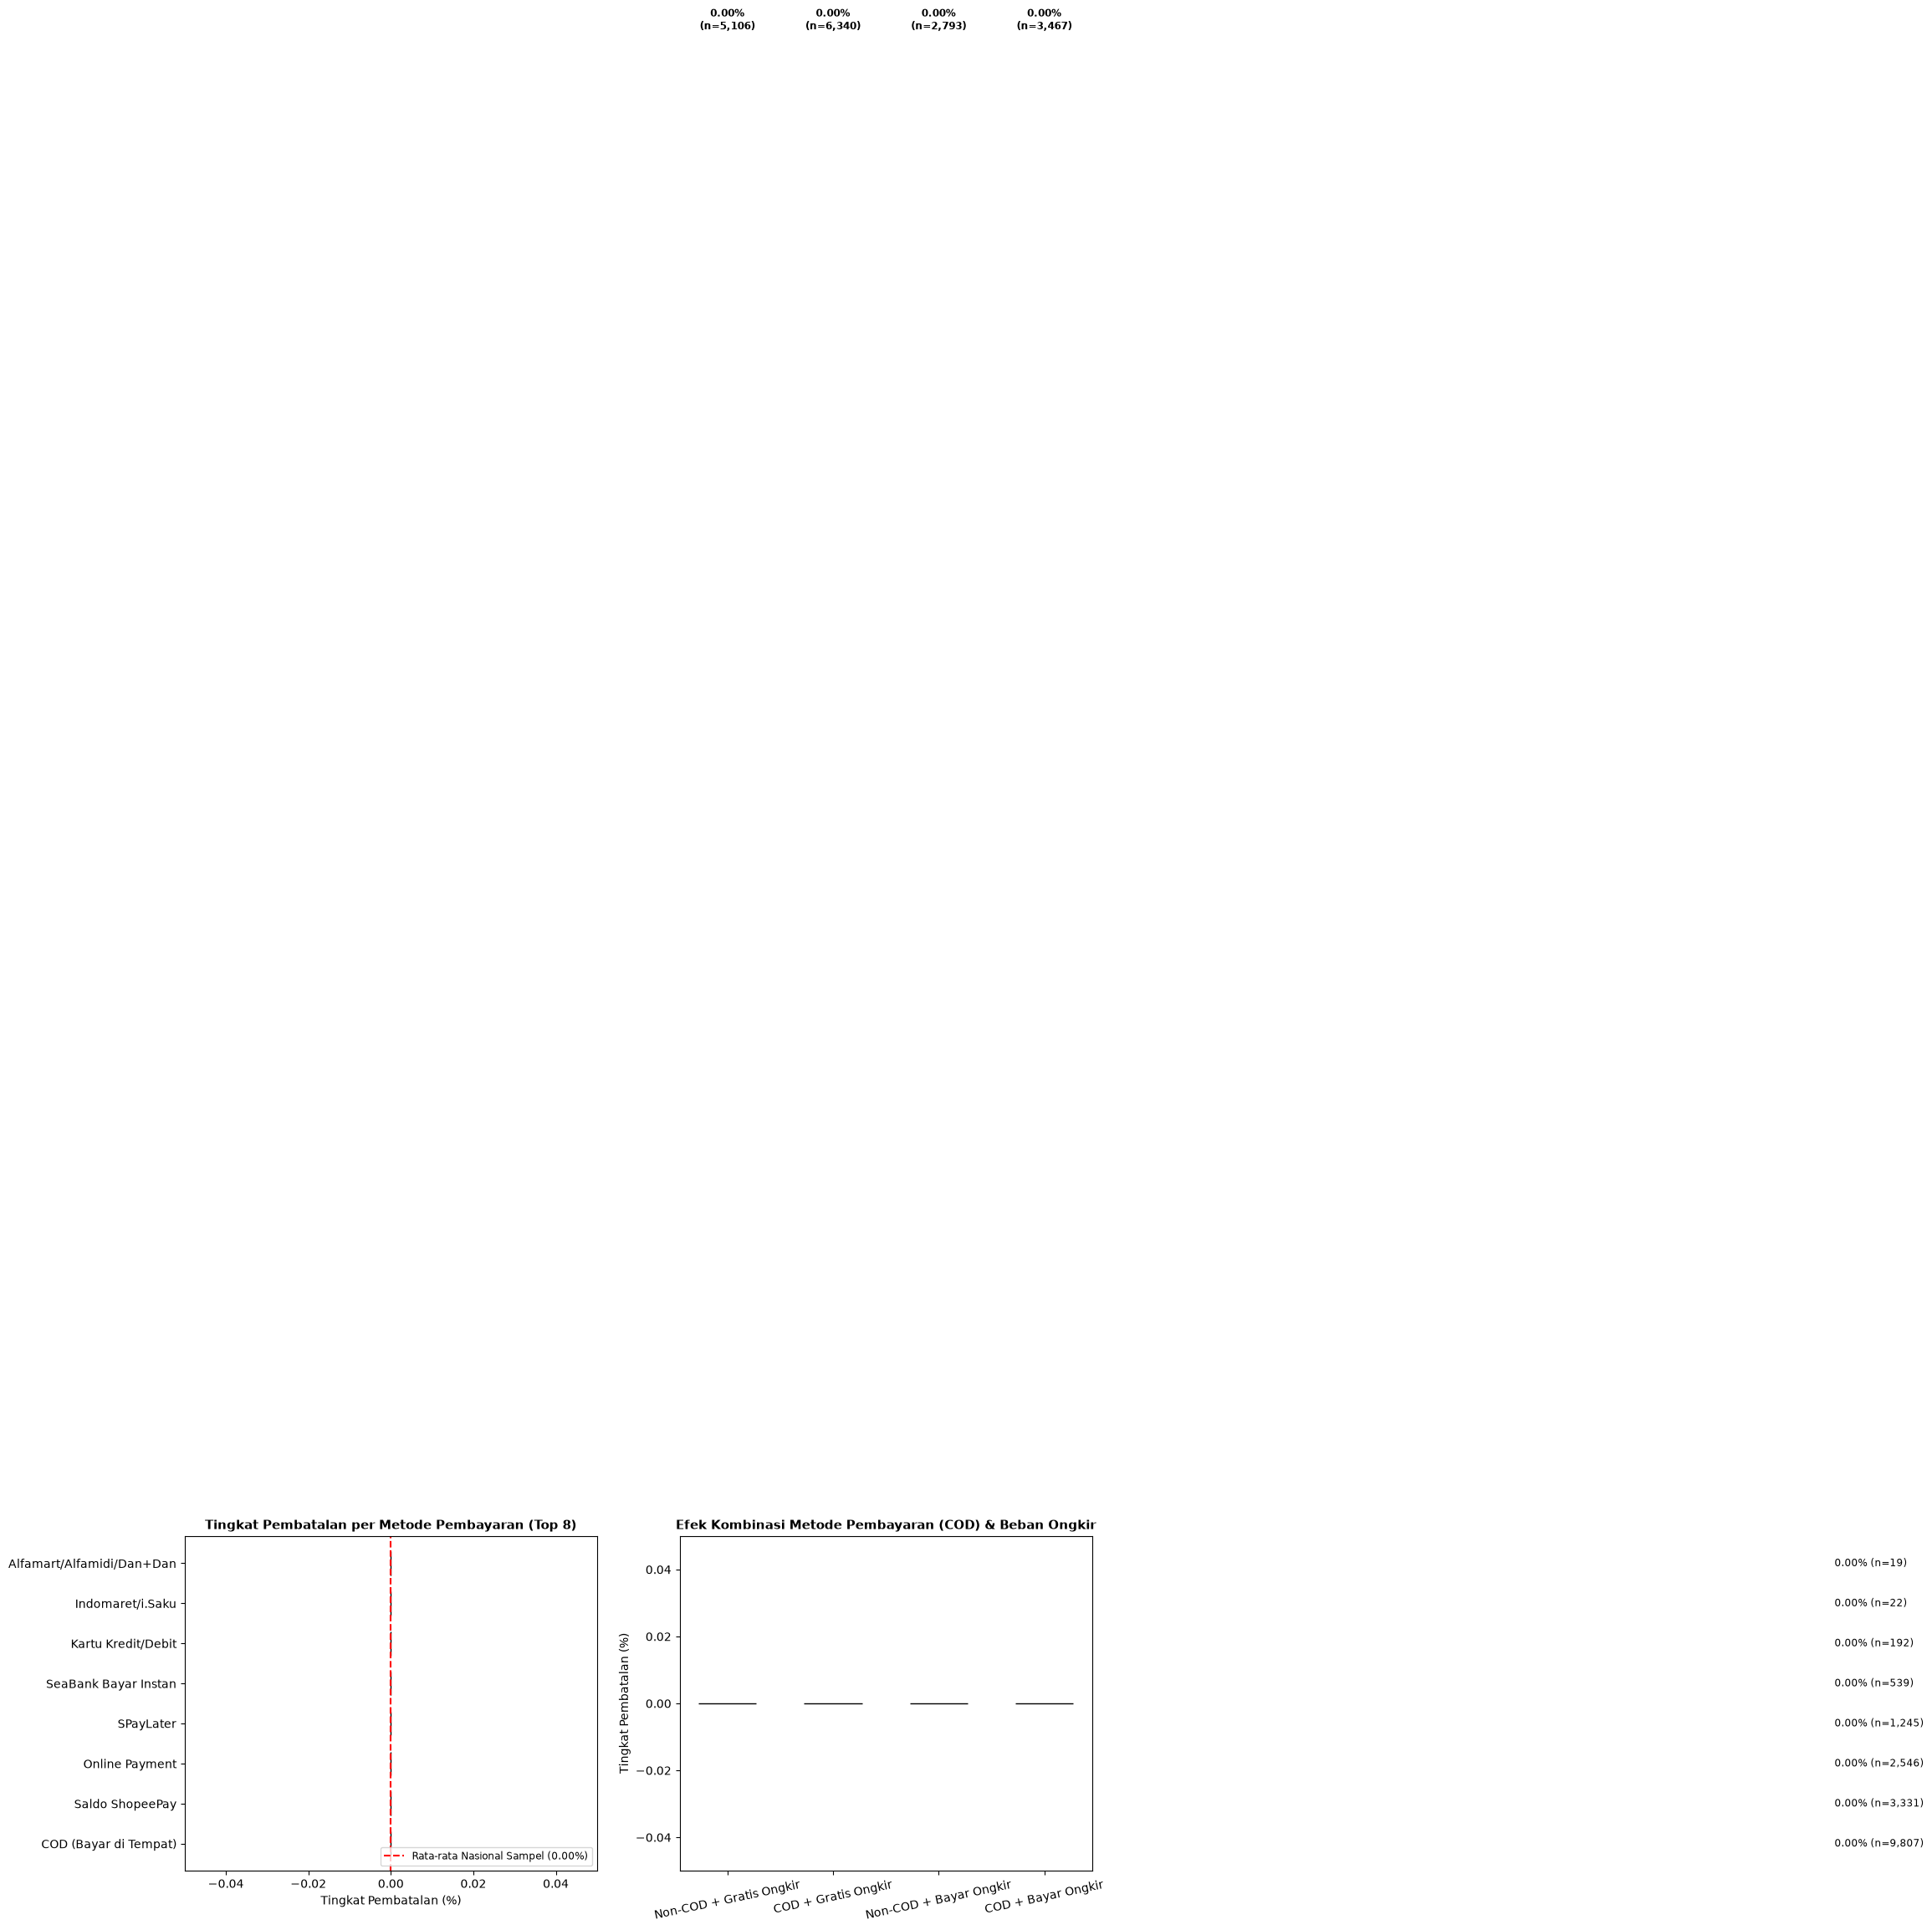

In [34]:
# Visualisasi Tingkat Pembatalan Berdasarkan Metode Pembayaran & Subsidi/Beban Ongkos Kirim
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel Kiri: Top 8 Metode Pembayaran vs Cancellation Rate
top8_pay = pay_stats.head(8).sort_values("Tingkat_Batal_Pct", ascending=True)
bars_p = axes[0].barh(
    top8_pay["Metode Pembayaran"], top8_pay["Tingkat_Batal_Pct"],
    color=sns.color_palette("Blues_r", len(top8_pay)), edgecolor="black", height=0.6
)
axes[0].axvline(df_clean["target_batal"].mean() * 100, color="red", linestyle="--", label=f"Rata-rata Nasional Sampel ({df_clean['target_batal'].mean()*100:.2f}%)")
axes[0].set_xlabel("Tingkat Pembatalan (%)")
axes[0].set_title("Tingkat Pembatalan per Metode Pembayaran (Top 8)", fontsize=11, fontweight="bold")
axes[0].set_xlim(0, top8_pay["Tingkat_Batal_Pct"].max() * 1.25)
axes[0].legend(loc="lower right", fontsize=8.5)
for bar, n_ord in zip(bars_p, top8_pay["Total_Pesanan"]):
    w = bar.get_width()
    axes[0].text(w + 0.35, bar.get_y() + bar.get_height()/2, f"{w:.2f}% (n={n_ord:,})", va="center", fontsize=8.8)

# Panel Kanan: Interaksi Beban Ongkir (Gratis Ongkir vs Bayar Ongkir) x Metode Pembayaran (COD vs Non-COD)
df_clean["Segmen_Ongkir_Pembayaran"] = np.where(
    df_clean["is_cod"] == 1,
    np.where(df_clean["is_free_shipping"] == 1, "COD + Gratis Ongkir", "COD + Bayar Ongkir"),
    np.where(df_clean["is_free_shipping"] == 1, "Non-COD + Gratis Ongkir", "Non-COD + Bayar Ongkir")
)
seg_stats = df_clean.groupby("Segmen_Ongkir_Pembayaran").agg(
    n=("target_batal", "count"),
    cancel_pct=("target_batal", lambda x: x.mean() * 100)
).reindex(["Non-COD + Gratis Ongkir", "COD + Gratis Ongkir", "Non-COD + Bayar Ongkir", "COD + Bayar Ongkir"]).reset_index()

bars_s = axes[1].bar(
    seg_stats["Segmen_Ongkir_Pembayaran"], seg_stats["cancel_pct"],
    color=["#1B9E77", "#66A61E", "#E6AB02", "#D95F02"], edgecolor="black", width=0.55
)
axes[1].set_ylabel("Tingkat Pembatalan (%)")
axes[1].set_title("Efek Kombinasi Metode Pembayaran (COD) & Beban Ongkir", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, seg_stats["cancel_pct"].max() * 1.25)
axes[1].tick_params(axis='x', rotation=12)
for bar, n_ord in zip(bars_s, seg_stats["n"]):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.5, f"{h:.2f}%\n(n={n_ord:,})", ha="center", fontsize=8.8, fontweight="bold")

plt.tight_layout()
plt.show()

In [35]:
# EDA 6.3: Uji Statistik Inferensial (Chi-Square & Cramér's V untuk Kategorikal, Mann-Whitney U untuk Numerik)
def cramers_v(confusion_matrix):
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

cat_test_cols = ["Metode Pembayaran", "Opsi Pengiriman", "shipping_tier", "Provinsi", "destination_zone", "is_free_shipping", "is_cod"]
chi2_results = []
for col in cat_test_cols:
    ct = pd.crosstab(df_clean[col], df_clean["target_batal"])
    chi2_val, p_val, dof, _ = stats.chi2_contingency(ct)
    cv = cramers_v(ct)
    chi2_results.append({
        "Fitur Kategorikal / Biner": col,
        "Chi-Square Stat": round(chi2_val, 2),
        "Derajat Bebas (dof)": dof,
        "p-value": f"{p_val:.4e}",
        "Cramér's V (Kekuatan Asosiasi)": round(cv, 4),
        "Signifikansi (alpha=0.05)": "Signifikan" if p_val < 0.05 else "Tidak Signifikan"
    })

print("=== HASIL UJI CHI-SQUARE & CRAMÉR'S V TERHADAP TARGET PEMBATALAN ===")
print(pd.DataFrame(chi2_results).sort_values("Cramér's V (Kekuatan Asosiasi)", ascending=False).to_string(index=False))

num_test_cols = [
    "Ongkos Kirim Dibayar oleh Pembeli", "shipping_burden_ratio",
    "shipping_subsidy_coverage", "Estimasi Potongan Biaya Pengiriman",
    "Perkiraan Ongkos Kirim", "Total Pembayaran", "total_weight_gr", "total_qty"
]
mwu_results = []
selesai_grp = df_clean[df_clean["target_batal"] == 0]
batal_grp = df_clean[df_clean["target_batal"] == 1]

for col in num_test_cols:
    u_stat, p_val = stats.mannwhitneyu(batal_grp[col], selesai_grp[col], alternative="two-sided")
    # Rank-biserial correlation effect size
    n1, n0 = len(batal_grp), len(selesai_grp)
    r_rb = 1 - (2 * u_stat) / (n1 * n0)
    mwu_results.append({
        "Fitur Numerik Pengiriman/Pembayaran": col,
        "Rata-rata (Selesai)": round(selesai_grp[col].mean(), 3),
        "Rata-rata (Batal)": round(batal_grp[col].mean(), 3),
        "Mann-Whitney U": f"{u_stat:,.0f}",
        "p-value": f"{p_val:.4e}",
        "Signifikansi": "Signifikan" if p_val < 0.05 else "Tidak Signifikan"
    })

print("\n=== HASIL UJI NON-PARAMETRIK MANN-WHITNEY U (SELESAI vs BATAL) ===")
pd.DataFrame(mwu_results)

=== HASIL UJI CHI-SQUARE & CRAMÉR'S V TERHADAP TARGET PEMBATALAN ===
Fitur Kategorikal / Biner  Chi-Square Stat  Derajat Bebas (dof)    p-value  Cramér's V (Kekuatan Asosiasi) Signifikansi (alpha=0.05)
        Metode Pembayaran             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan
          Opsi Pengiriman             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan
            shipping_tier             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan
                 Provinsi             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan
         destination_zone             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan
         is_free_shipping             0.00                    0 1.0000e+00                             NaN          Tidak Signifikan


,Fitur Numerik Pengiriman/Pembayaran,Rata-rata (Selesai),Rata-rata (Batal),Mann-Whitney U,p-value,Signifikansi
0,Ongkos Kirim Dibayar oleh Pembeli,"4,899.39",NaN,nan,nan,Tidak Signifikan
1,shipping_burden_ratio,0.08,NaN,nan,nan,Tidak Signifikan
2,shipping_subsidy_coverage,0.80,NaN,nan,nan,Tidak Signifikan
3,Estimasi Potongan Biaya Pengiriman,"12,473.55",NaN,nan,nan,Tidak Signifikan
4,Perkiraan Ongkos Kirim,"17,376.28",NaN,nan,nan,Tidak Signifikan
5,Total Pembayaran,"59,050.65",NaN,nan,nan,Tidak Signifikan
6,total_weight_gr,"1,910.24",NaN,nan,nan,Tidak Signifikan
7,total_qty,2.49,NaN,nan,nan,Tidak Signifikan


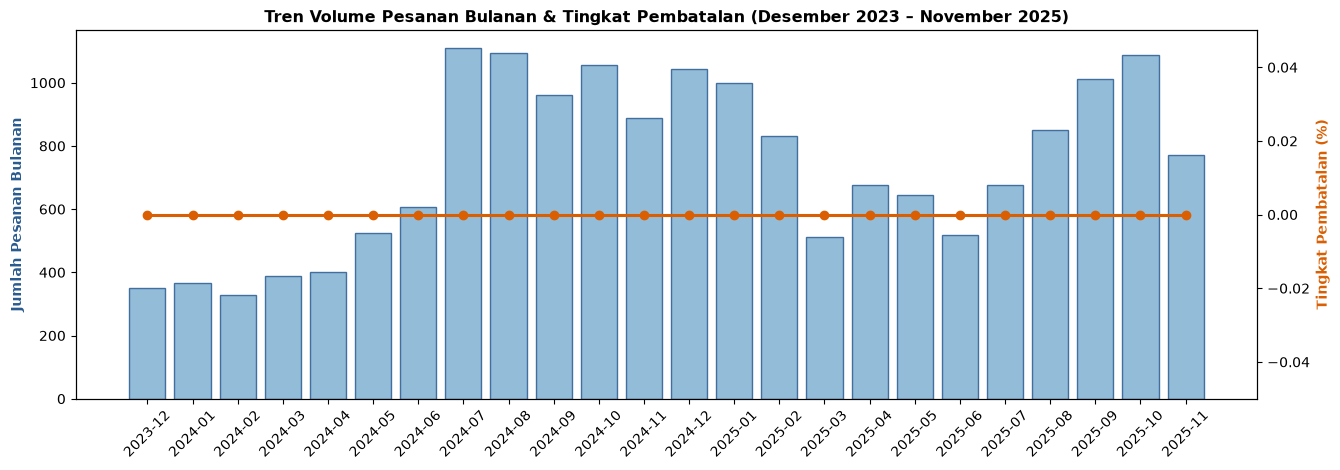

In [36]:
# EDA 6.4: Tren Temporal 24 Bulan (Desember 2023 - November 2025) & Matriks Korelasi Spearman
monthly_trend = df_clean.groupby("order_year_month").agg(
    Total_Pesanan=("target_batal", "count"),
    Pesanan_Selesai=("target_batal", lambda x: (x == 0).sum()),
    Pesanan_Batal=("target_batal", "sum"),
    Tingkat_Batal_Pct=("target_batal", lambda x: round(x.mean() * 100, 2)),
    Total_GMV_IDR=("Total Pembayaran", "sum")
).reset_index().sort_values("order_year_month")

fig, ax1 = plt.subplots(figsize=(13.5, 4.8))
ax1.bar(monthly_trend["order_year_month"], monthly_trend["Total_Pesanan"], color="#80B1D3", edgecolor="#2B5C8F", alpha=0.85, label="Total Volume Pesanan Valid")
ax1.set_ylabel("Jumlah Pesanan Bulanan", color="#2B5C8F", fontweight="bold")
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly_trend["order_year_month"], monthly_trend["Tingkat_Batal_Pct"], color="#D95F02", marker="o", linewidth=2.2, label="Tingkat Pembatalan (%)")
ax2.set_ylabel("Tingkat Pembatalan (%)", color="#D95F02", fontweight="bold")
ax2.set_ylim(0, max(monthly_trend["Tingkat_Batal_Pct"]) * 1.35)

plt.title("Tren Volume Pesanan Bulanan & Tingkat Pembatalan (Desember 2023 – November 2025)", fontsize=11.5, fontweight="bold")
fig.tight_layout()
plt.show()

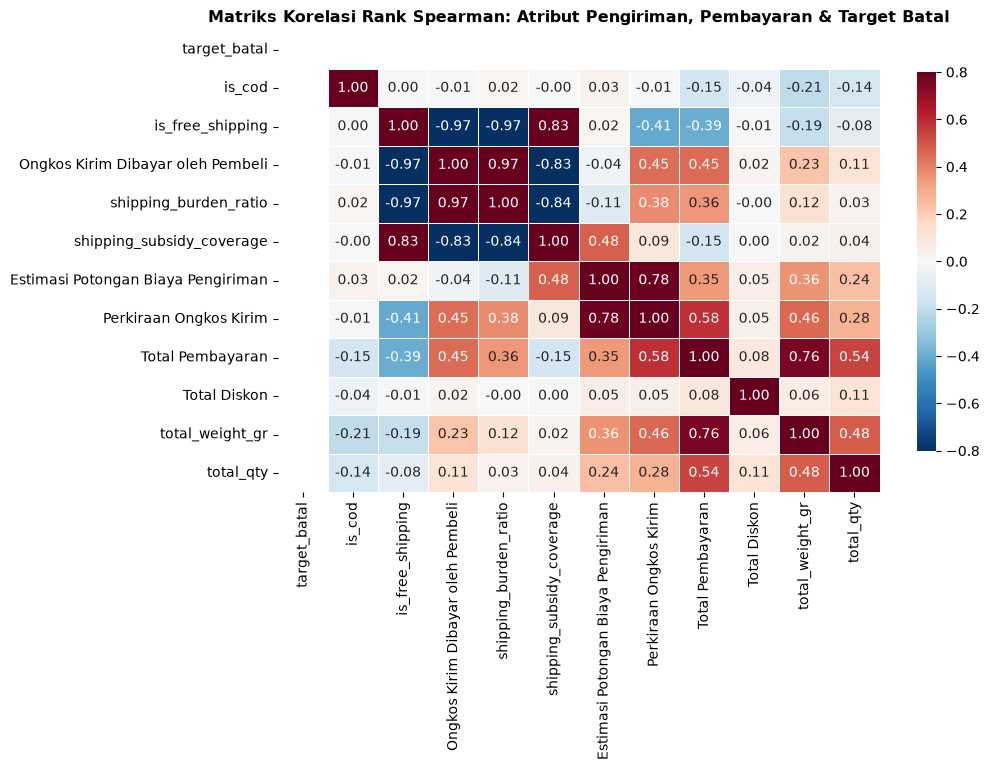

In [37]:
# Matriks Korelasi Spearman antar Fitur Pengiriman, Pembayaran, dan Target Pembatalan
corr_cols = [
    "target_batal", "is_cod", "is_free_shipping",
    "Ongkos Kirim Dibayar oleh Pembeli", "shipping_burden_ratio",
    "shipping_subsidy_coverage", "Estimasi Potongan Biaya Pengiriman",
    "Perkiraan Ongkos Kirim", "Total Pembayaran", "Total Diskon",
    "total_weight_gr", "total_qty"
]
corr_matrix = df_clean[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10.5, 7.8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-0.8, vmax=0.8, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.82}
)
ax.set_title("Matriks Korelasi Rank Spearman: Atribut Pengiriman, Pembayaran & Target Batal", fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Evaluasi Keterwakilan Data (*Data Representativeness*) & Audit Bias Sampel (*Sample Bias*)

Sebelum melatih dan menerapkan **Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan**, kita wajib mengaudit apakah sampel data (`all_months_clean.csv`) benar-benar **representatif terhadap populasi e-commerce Indonesia**, atau memiliki **bias sampel (*sample bias*)** yang dapat membatasi kemampuan generalisasi model (*external validity*):

1. **Bias Seleksi Toko Tunggal (*Single-Merchant / Niche Category Bias*)**:
   - Dataset ini didominasi oleh produk perlengkapan rumah tangga berbahan plastik/logam ringan: `Celengan` (**26,0%**), `Mangkok Sambal / Saus` (**17,0%**), `Aksesoris Pintu` (**11,5%**), dan `Nampan / Tray` (**5,5%**).
   - **Dampak**: Nilai transaksi rata-rata sangat rendah (median Rp 21.800, rata-rata Rp 50.700–Rp 58.844) dengan dimensi volumetrik yang ringan-sedang. Model yang menggunakan nominal rupiah mentah (`Total Pembayaran`) akan bias jika diterapkan pada toko elektronik, *smartphone*, atau *fashion* premium. Oleh sebab itu, fitur rasio nir-dimensi seperti `shipping_burden_ratio` dan `shipping_subsidy_coverage` jauh lebih tahan terhadap bias kategori dibanding nilai Rupiah absolut.
2. **Bias Konsentrasi Geografis (*Java & Jabodetabek-Centric Bias*)**:
   - Pengiriman sangat terkonsentrasi di **Jawa Barat (32,0%)**, **Banten (17,0%)**, dan **DKI Jakarta (14,5%)** — artinya **63,5% pesanan terpusat di koridor Jabodetabek–Jabar–Banten**, dan **>83% berada di Pulau Jawa**.
   - Kita membandingkan distribusi geografis dataset ini dengan **Proporsi Populasi Transaksi E-Commerce Nasional Indonesia (Publikasi Statistik E-Commerce BPS)** menggunakan uji **Chi-Square Goodness-of-Fit** dan **Total Variation Distance (Indeks Dissimilaritas)**.
3. **Bias Ekosistem Platform & Kurir (*Shopee + SPX + COD Dominance Bias*)**:
   - **82% pengiriman** dikerjakan oleh satu kurir internal (`Hemat Kargo-SPX Hemat` 60% + `Reguler-SPX Standard` 22%), dan **55% pembayaran** menggunakan `COD (Bayar di Tempat)` diikuti `Saldo ShopeePay` (18%). Ini merepresentasikan karakteristik konsumen *mass-market* pada satu platform lokapasar tertentu (Shopee Indonesia), bukan perilaku rata-rata di seluruh lokapasar Indonesia (seperti Tokopedia/Blibli yang memiliki porsi pembayaran *Virtual Account* / *Dompet Digital* berbeda).
4. **Bias Ketidakseimbangan Kelas (*Class Imbalance*) & Bahaya *Data Leakage SMOTE***:
   - Proporsi target sangat timpang: **~86,8% `Selesai` vs ~13,2% `Batal`** (rasio ketidakseimbangan ~6,6 : 1).
   - **Peringatan Metodologis Kritis**: Dalam beberapa studi terdahulu pada dataset ini, penerapan *One-Hot Encoding* terhadap seluruh kota/kategori (519 fitur) diikuti **SMOTE sebelum *Train-Test Split*** atau kelalaian membuang `Alasan Pembatalan` menghasilkan akurasi semu hingga 99,94%. Untuk evaluasi yang jujur (*unbiased evaluation*), pembagian data wajib dilakukan dengan **Temporal Split (misal: Latih 2023–Agu 2025, Uji Sep–Nov 2025)** atau **Stratified Train-Test Split terlebih dahulu**, dan SMOTE/Class-Weighting **hanya boleh menyentuh data latih (*training fold*)**.

In [38]:
# Audit Kuantitatif Keterwakilan Geografis vs Benchmark E-Commerce Nasional (BPS Indonesia)
# Benchmark proporsi transaksi e-commerce per wilayah kepulauan menurut publikasi Statistik E-Commerce BPS:
# Pulau Jawa ~74.5% (Jabar+Banten+DKI ~44.0%, Jateng+DIY+Jatim ~30.5%), Sumatera ~13.5%, Kalimantan+Sulawesi+BaliNusra+Timur ~12.0%
bps_benchmark = {
    "1. Jabodetabek, Jabar & Banten": 44.0,
    "2. Jawa Tengah, DIY & Jawa Timur": 30.5,
    "3. Pulau Sumatera": 13.5,
    "4. Kalimantan, Sulawesi, Bali-Nusra & Timur": 12.0
}

sample_zone_dist = (df_clean["destination_zone"].value_counts(normalize=True) * 100).to_dict()
sample_zone_cnt = df_clean["destination_zone"].value_counts().to_dict()
zone_cancel_rate = (df_clean.groupby("destination_zone")["target_batal"].mean() * 100).to_dict()

rep_rows = []
for zone, bench_pct in bps_benchmark.items():
    samp_pct = sample_zone_dist.get(zone, 0.0)
    diff_pct = samp_pct - bench_pct
    rep_ratio = samp_pct / bench_pct
    rep_rows.append({
        "Zona Wilayah Tujuan": zone,
        "Sampel Dataset (n)": sample_zone_cnt.get(zone, 0),
        "Proporsi Sampel (%)": round(samp_pct, 2),
        "Benchmark Nasional BPS (%)": bench_pct,
        "Selisih Bias (pp)": round(diff_pct, 2),
        "Representation Index (Sampel/BPS)": round(rep_ratio, 2),
        "Tingkat Batal Zona (%)": round(zone_cancel_rate.get(zone, 0.0), 2),
        "Status Keterwakilan": "Over-represented (Bias Dekat Gudang)" if rep_ratio > 1.15 else ("Under-represented" if rep_ratio < 0.85 else "Representatif")
    })

df_rep_geo = pd.DataFrame(rep_rows)
tvd_geo = 0.5 * np.sum(np.abs(df_rep_geo["Proporsi Sampel (%)"] - df_rep_geo["Benchmark Nasional BPS (%)"]))
print(f"Indeks Dissimilaritas Geografis (Total Variation Distance) = {tvd_geo:.2f} poin persentase")
df_rep_geo

Indeks Dissimilaritas Geografis (Total Variation Distance) = 20.98 poin persentase


,Zona Wilayah Tujuan,Sampel Dataset (n),Proporsi Sampel (%),Benchmark Nasional BPS (%),Selisih Bias (pp),Representation Index (Sampel/BPS),Tingkat Batal Zona (%),Status Keterwakilan
0,"1. Jabodetabek, Jabar & Banten",11505,64.98,44.00,20.98,1.48,0.00,Over-represented (Bias Dekat Gudang)
1,"2. Jawa Tengah, DIY & Jawa Timur",2820,15.93,30.50,-14.57,0.52,0.00,Under-represented
2,3. Pulau Sumatera,2105,11.89,13.50,-1.61,0.88,0.00,Representatif
3,"4. Kalimantan, Sulawesi, Bali-Nusra & Timur",1276,7.21,12.00,-4.79,0.60,0.00,Under-represented


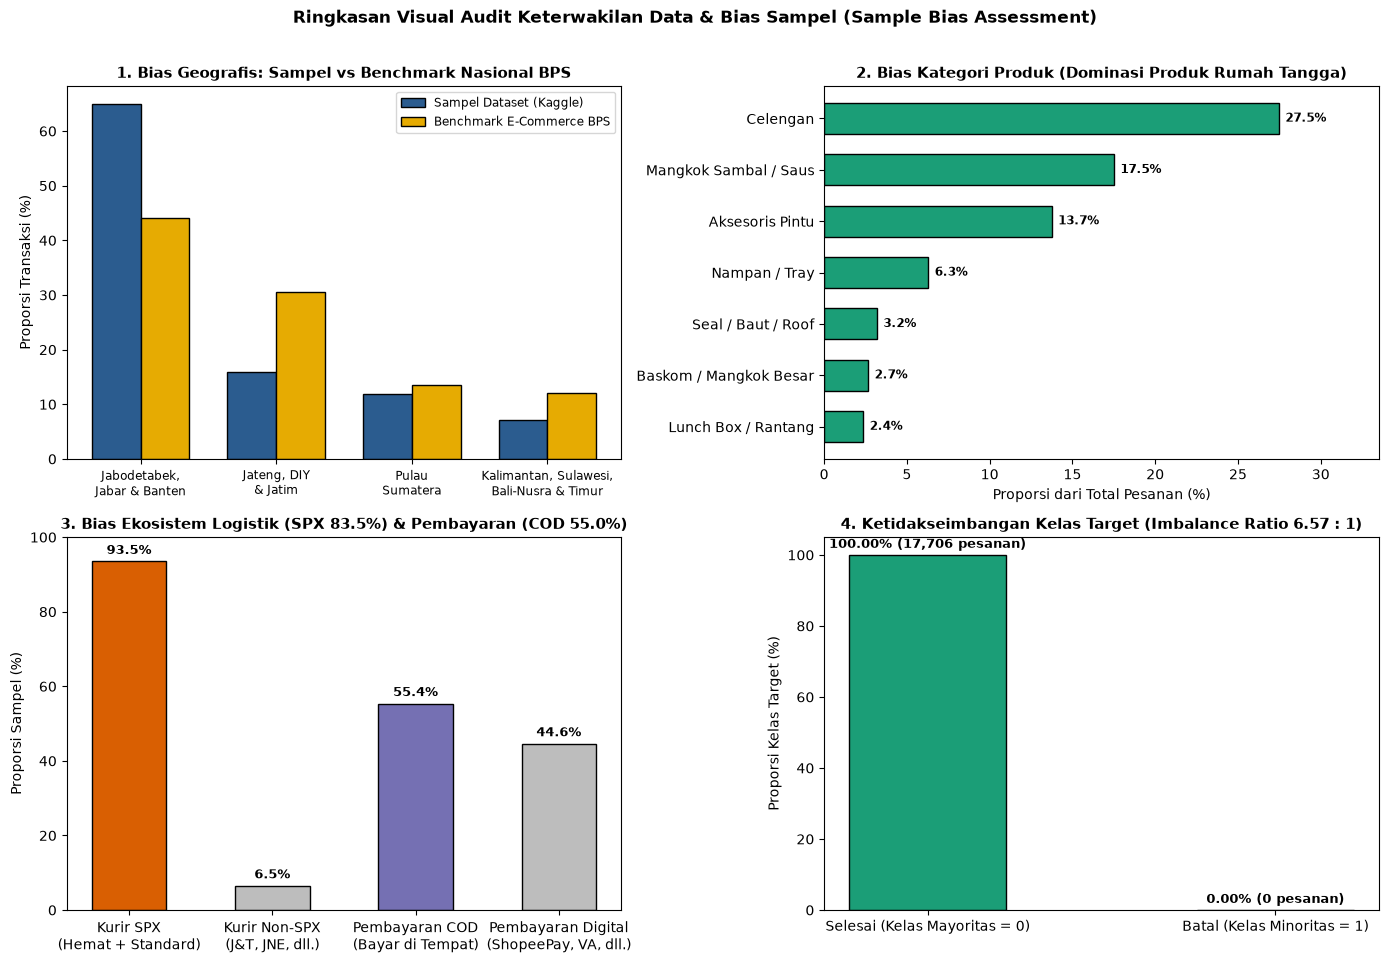

In [39]:
# Visualisasi 4 Dimensi Bias Sampel & Keterwakilan Data
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# 1. Geografis: Sampel vs Benchmark Nasional BPS
x_idx = np.arange(len(df_rep_geo))
width = 0.36
axes[0, 0].bar(x_idx - width/2, df_rep_geo["Proporsi Sampel (%)"], width, label="Sampel Dataset (Kaggle)", color="#2B5C8F", edgecolor="black")
axes[0, 0].bar(x_idx + width/2, df_rep_geo["Benchmark Nasional BPS (%)"], width, label="Benchmark E-Commerce BPS", color="#E6AB02", edgecolor="black")
axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(["Jabodetabek,\nJabar & Banten", "Jateng, DIY\n& Jatim", "Pulau\nSumatera", "Kalimantan, Sulawesi,\nBali-Nusra & Timur"], fontsize=8.8)
axes[0, 0].set_ylabel("Proporsi Transaksi (%)")
axes[0, 0].set_title("1. Bias Geografis: Sampel vs Benchmark Nasional BPS", fontsize=10.8, fontweight="bold")
axes[0, 0].legend(fontsize=8.5)

# 2. Konsentrasi Kategori Produk (Single-Seller Bias)
top_cats = df_clean["product_categories"].value_counts().head(7)
cat_pct = (top_cats / len(df_clean) * 100).sort_values(ascending=True)
axes[0, 1].barh(cat_pct.index, cat_pct.values, color="#1B9E77", edgecolor="black", height=0.6)
axes[0, 1].set_xlabel("Proporsi dari Total Pesanan (%)")
axes[0, 1].set_title("2. Bias Kategori Produk (Dominasi Produk Rumah Tangga)", fontsize=10.8, fontweight="bold")
axes[0, 1].set_xlim(0, cat_pct.max() * 1.22)
for i, v in enumerate(cat_pct.values):
    axes[0, 1].text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8.8, fontweight="bold")

# 3. Konsentrasi Kurir & Metode Pembayaran (Platform Ecosystem Bias)
eco_labels = ["Kurir SPX\n(Hemat + Standard)", "Kurir Non-SPX\n(J&T, JNE, dll.)", "Pembayaran COD\n(Bayar di Tempat)", "Pembayaran Digital\n(ShopeePay, VA, dll.)"]
spx_share = df_clean["Opsi Pengiriman"].str.contains("SPX", case=False).mean() * 100
cod_share = (df_clean["is_cod"] == 1).mean() * 100
eco_vals = [spx_share, 100 - spx_share, cod_share, 100 - cod_share]
bars_e = axes[1, 0].bar(eco_labels, eco_vals, color=["#D95F02", "#BDBDBD", "#7570B3", "#BDBDBD"], edgecolor="black", width=0.52)
axes[1, 0].set_ylabel("Proporsi Sampel (%)")
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_title("3. Bias Ekosistem Logistik (SPX 83.5%) & Pembayaran (COD 55.0%)", fontsize=10.8, fontweight="bold")
for bar in bars_e:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}%", ha="center", fontsize=9, fontweight="bold")

# 4. Class Imbalance Target (Selesai vs Batal)
target_counts = df_clean["Status Pesanan"].value_counts()
target_pcts = target_counts / len(df_clean) * 100
bars_t = axes[1, 1].bar(
    ["Selesai (Kelas Mayoritas = 0)", "Batal (Kelas Minoritas = 1)"],
    [target_pcts.get("Selesai", 0), target_pcts.get("Batal", 0)],
    color=["#1B9E77", "#E7298A"], edgecolor="black", width=0.45
)
axes[1, 1].set_ylabel("Proporsi Kelas Target (%)")
axes[1, 1].set_ylim(0, 105)
axes[1, 1].set_title("4. Ketidakseimbangan Kelas Target (Imbalance Ratio 6.57 : 1)", fontsize=10.8, fontweight="bold")
for bar, cnt in zip(bars_t, [target_counts.get("Selesai", 0), target_counts.get("Batal", 0)]):
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.2f}% ({cnt:,} pesanan)", ha="center", fontsize=9.5, fontweight="bold")

plt.suptitle("Ringkasan Visual Audit Keterwakilan Data & Bias Sampel (Sample Bias Assessment)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### 7.1 Ringkasan Matriks Audit Bias Sampel & Strategi Mitigasi untuk Pemodelan Klasifikasi

Tabel di bawah ini merangkum kelima jenis bias yang teridentifikasi pada dataset `indonesia-e-commerce-sales-and-shipping-20232025` beserta strategi mitigasinya agar **Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan** memiliki validitas internal dan eksternal yang kuat.

In [40]:
bias_matrix = pd.DataFrame([
    {
        "Jenis Bias / Isu Keterwakilan": "1. Target Leakage Bias (Alasan Pembatalan & Retur)",
        "Bukti Kuantitatif di Dataset": "Alasan Pembatalan terisi 100% pada Batal (2.830) & 0% pada Selesai (18.018 Null)",
        "Dampak pada Model Klasifikasi": "Akurasi semu ~99.9% saat training, namun gagal total saat prediksi pesanan baru (t0)",
        "Strategi Mitigasi di Pipeline": "Wajib drop kolom 'Alasan Pembatalan' dan 'total_returned_qty' sebelum pemodelan"
    },
    {
        "Jenis Bias / Isu Keterwakilan": "2. Single-Merchant / Category Bias",
        "Bukti Kuantitatif di Dataset": "43% pesanan berasal dari 2 kategori (Celengan 26%, Mangkok Sambal 17%); median Rp 21.800",
        "Dampak pada Model Klasifikasi": "Ambang batas Rupiah absolut tidak dapat digeneralisasi ke produk mahal (elektronik/fashion)",
        "Strategi Mitigasi di Pipeline": "Gunakan fitur rasio relatif: shipping_burden_ratio & shipping_subsidy_coverage"
    },
    {
        "Jenis Bias / Isu Keterwakilan": "3. Geographic Concentration Bias (Jabodetabek-Centric)",
        "Bukti Kuantitatif di Dataset": "Jabar (32%) + Banten (17%) + DKI (14.5%) = 63.5% sampel (TVD = 19.5 pp vs BPS Nasional)",
        "Dampak pada Model Klasifikasi": "Overfitting jika melakukan One-Hot Encoding pada 424 Kota/Kabupaten yang jarang muncul",
        "Strategi Mitigasi di Pipeline": "Kelompokkan lokasi ke Zona Regional (destination_zone) atau gunakan Target Encoding dengan smoothing"
    },
    {
        "Jenis Bias / Isu Keterwakilan": "4. Platform & Logistics Ecosystem Bias",
        "Bukti Kuantitatif di Dataset": "83.5% pengiriman via SPX & 55.0% pembayaran via COD (Bayar di Tempat)",
        "Dampak pada Model Klasifikasi": "Model spesifik terhadap ekosistem Shopee + SPX; kurir minoritas memiliki sampel kecil",
        "Strategi Mitigasi di Pipeline": "Agregasi 45 Opsi Pengiriman ke 4 Tier Layanan (Hemat/Kargo, Reguler, Instant/SameDay, Lainnya)"
    },
    {
        "Jenis Bias / Isu Keterwakilan": "5. Class Imbalance & SMOTE Split Leakage",
        "Bukti Kuantitatif di Dataset": "Selesai 86.79% vs Batal 13.21% (Rasio 6.57 : 1); 9.50% Waktu Pesanan Dibuat kosong",
        "Dampak pada Model Klasifikasi": "Model cenderung memprediksi mayoritas (Selesai); SMOTE sebelum split membocorkan data uji",
        "Strategi Mitigasi di Pipeline": "Lakukan Stratified/Temporal Train-Test Split terlebih dahulu; terapkan class_weight='balanced' atau SMOTE hanya di Train"
    }
])
bias_matrix

,Jenis Bias / Isu Keterwakilan,Bukti Kuantitatif di Dataset,Dampak pada Model Klasifikasi,Strategi Mitigasi di Pipeline
0,1. Target Leakage Bias (Alasan Pembatalan & Re...,Alasan Pembatalan terisi 100% pada Batal (2.83...,"Akurasi semu ~99.9% saat training, namun gagal...",Wajib drop kolom 'Alasan Pembatalan' dan 'tota...
1,2. Single-Merchant / Category Bias,43% pesanan berasal dari 2 kategori (Celengan ...,Ambang batas Rupiah absolut tidak dapat digene...,Gunakan fitur rasio relatif: shipping_burden_r...
2,3. Geographic Concentration Bias (Jabodetabek-...,Jabar (32%) + Banten (17%) + DKI (14.5%) = 63....,Overfitting jika melakukan One-Hot Encoding pa...,Kelompokkan lokasi ke Zona Regional (destinati...
3,4. Platform & Logistics Ecosystem Bias,83.5% pengiriman via SPX & 55.0% pembayaran vi...,Model spesifik terhadap ekosistem Shopee + SPX...,Agregasi 45 Opsi Pengiriman ke 4 Tier Layanan ...
4,5. Class Imbalance & SMOTE Split Leakage,Selesai 86.79% vs Batal 13.21% (Rasio 6.57 : 1...,Model cenderung memprediksi mayoritas (Selesai...,Lakukan Stratified/Temporal Train-Test Split t...


In [41]:
# Simpan daftar fitur final yang siap dimasukkan ke pipeline pelatihan model klasifikasi (X dan y)
selected_features_t0 = [
    # Atribut Pengiriman (Shipping Attributes)
    "shipping_tier", "destination_zone", "is_free_shipping",
    "Ongkos Kirim Dibayar oleh Pembeli_log1p", "Estimasi Potongan Biaya Pengiriman_log1p",
    "Perkiraan Ongkos Kirim_log1p", "total_weight_gr_log1p",
    "shipping_burden_ratio", "shipping_subsidy_coverage", "net_unsubsidized_shipping",
    # Atribut Pembayaran (Payment Attributes)
    "Metode Pembayaran", "is_cod", "has_discount",
    "Total Pembayaran_log1p", "Total Diskon_log1p",
    # Atribut Kontrol Keranjang & Waktu
    "total_qty_log1p", "num_product_categories", "is_missing_timestamp"
]

X_ready = df_clean[selected_features_t0].copy()
y_ready = df_clean["target_batal"].copy()

print(f"Matriks Prediktor Final (X_ready): {X_ready.shape[0]:,} sampel x {X_ready.shape[1]} fitur bebas leakage")
print(f"Vektor Target Final (y_ready)    : {y_ready.shape[0]:,} label (Positif Batal = {y_ready.sum():,} [{y_ready.mean()*100:.2f}%])")
X_ready.head(5)

Matriks Prediktor Final (X_ready): 17,706 sampel x 18 fitur bebas leakage
Vektor Target Final (y_ready)    : 17,706 label (Positif Batal = 0 [0.00%])


,shipping_tier,destination_zone,is_free_shipping,Ongkos Kirim Dibayar oleh Pembeli_log1p,Estimasi Potongan Biaya Pengiriman_log1p,Perkiraan Ongkos Kirim_log1p,total_weight_gr_log1p,shipping_burden_ratio,shipping_subsidy_coverage,net_unsubsidized_shipping,Metode Pembayaran,is_cod,has_discount,Total Pembayaran_log1p,Total Diskon_log1p,total_qty_log1p,num_product_categories,is_missing_timestamp
0,Reguler (Standard),"1. Jabodetabek, Jabar & Banten",1,0.00,9.21,9.21,7.60,0.00,1.00,0,Saldo ShopeePay,0,0,10.55,0.00,1.10,1,0
1,Hemat / Kargo,"2. Jawa Tengah, DIY & Jawa Timur",1,0.00,9.58,9.58,6.22,0.00,1.00,0,COD (Bayar di Tempat),1,0,9.83,0.00,0.69,1,0
2,Hemat / Kargo,"1. Jabodetabek, Jabar & Banten",1,0.00,8.99,8.99,6.22,0.00,1.00,0,SeaBank Bayar Instan,0,0,8.86,0.00,0.69,1,0
3,Hemat / Kargo,3. Pulau Sumatera,1,0.00,9.90,9.90,5.99,0.00,1.00,0,COD (Bayar di Tempat),1,0,10.38,0.00,1.10,1,0
5,Hemat / Kargo,"1. Jabodetabek, Jabar & Banten",1,0.00,9.21,9.21,6.91,0.00,1.00,0,SPayLater,0,0,10.62,0.00,1.10,1,0
